# Both sheets explained simply

- **1** (sheet *Psychrometrics challenge*): "How much **water** hides in the air, and how much **energy** does the air carry?" — **Part A**
- **2** (sheet *Lab 2*): "Will a **person** feel comfortable in that air?" — **Part B**

**How they connect:** sheet 1 is about the **air**, sheet 2 is about the **person standing in the air**. The amount of water in the air that you find in Part A is also needed by the body calculation in Part B.

In [1]:
import sys; sys.path.insert(0, "../../../shared")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from calculate_pmv_ppd import calculate_pmv_ppd

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
SUMMER, WINTER = ORANGE, BLUE      # orange = summer, blue = winter, everywhere

from matplotlib.patches import Ellipse

def ring(ax, x, y, size=24, color=INK):                      # circle around one point of interest
    ax.plot(x, y, "o", ms=size, mfc="none", mec=color, mew=2, zorder=6, clip_on=False)

def point(ax, xy, text, xytext, color=INK, ha="center"):     # text with an arrow pointing at xy
    ax.annotate(text, xy, xytext=xytext, textcoords="offset points", color=color, fontsize=8.5, ha=ha, bbox=dict(fc="white", ec="none", alpha=0.75, pad=1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3, shrinkA=3, shrinkB=3), zorder=7)

def blob(ax, xs, ys, color, padx, pady):                     # dashed oval around a group of points
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    ax.add_patch(Ellipse(((xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2), np.ptp(xs) * 1.45 + padx, np.ptp(ys) * 1.45 + pady,
                         fill=False, ec=color, lw=2, ls="--", zorder=6))

# Part A: Sheet 1, the air and its hidden water

**Moist air** is the air around us: **dry air plus a little invisible water** (water vapour). **Psychrometrics** is the science of "how much water is in the air".

## A1. How much does the air in a room weigh?

Air feels like nothing, but it has weight. The room is 6 m × 4 m × 3 m, at 25 °C and normal pressure. **Pressure** is how hard the air pushes on things. It is measured in **pascals** (Pa), and normal air pressure is 100 000 Pa (1 bar).

**Recipe** (the "ideal gas law": pressure × volume = mass × R × temperature; an *ideal gas* is a gas simple enough to follow it, and we treat air like that):

$$m = \frac{p\cdot V}{R\cdot T}$$

- $p$ = 100 000 Pa and $V$ is the volume of the room (72 m³)
- $R$ = 287 J/(kg·K) is a number for air
- $T$ is the temperature in kelvin (always add 273.15 to the °C value)

![Even air has weight: this room holds as much air as a person weighs, more than once](../images/air-parcel-room.svg)

*Figure: Even air has weight: this room holds as much air as a person weighs, more than once*

The room has 72 m3 of air. It weighs 84.1 kg (about 1.2 adults!). Density = 1.17 kg/m3


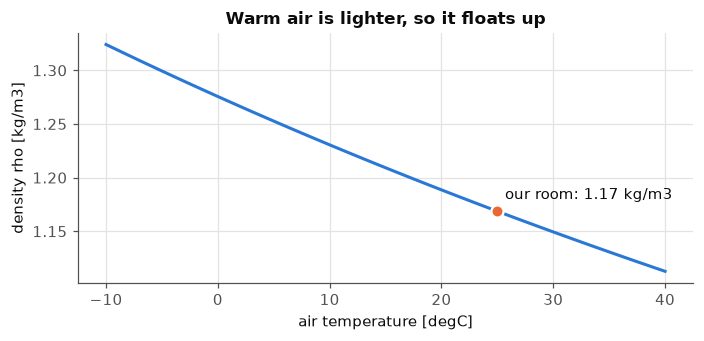

In [2]:
p, R = 1e5, 287
V = 6 * 4 * 3                       # m3
T = 25 + 273.15                     # K
m = p * V / (R * T)                 # kg of air in the room
rho = m / V                         # kg per m3 ("density" = how heavy each cubic metre is)
print(f"The room has {V} m3 of air. It weighs {m:.1f} kg (about {m/70:.1f} adults!). Density = {rho:.2f} kg/m3")

t = np.linspace(-10, 40, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, p / (R * (t + 273.15)), color=BLUE, lw=2)
ax.plot(25, rho, "o", color=ORANGE, ms=8, mec="white", mew=1.5)
ax.annotate(f"our room: {rho:.2f} kg/m3", (25, rho), xytext=(5, 8), textcoords="offset points")
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("density rho [kg/m3]")
ax.set_title("Warm air is lighter, so it floats up")
plt.tight_layout(); plt.show()

**Reading it.** When air gets warm it spreads out, so each cubic metre holds less stuff and weighs less. That is why warm air rises (hot-air balloons!). Our room's air weighs about **84 kg**.

## A2. The sponge: warm air holds much more water

The sheet gives a table: for each temperature, the **biggest** water pressure the air can hold, the **saturation pressure** $p_{sat}$. Between table rows we draw a straight line (interpolation).

**What does "100 % humidity" mean?** Think of the air as a sponge that can soak up water vapour. How much it can hold depends on the temperature: that biggest amount is $p_{sat}$. The water that is really in the air is the **partial vapour pressure** $p_v$: how hard the water part alone pushes (in Pa); more water means a bigger number. **Relative humidity** is how full the sponge is:

$$\varphi=\frac{p_v}{p_{sat}}$$

- **100 %** = the sponge is **completely full** at this temperature. One more drop would not fit, it turns into liquid (dew, fog, a cloud). "100 % humidity", "100 % relative humidity" and "saturated" all mean this same thing.
- It does **not** mean the air is made of water. A full sponge at 10 °C only holds a few grams of water per kilogram of air.
- **60 %** = the sponge is 60 % full. **0 %** = completely dry.
- The **black curve** in the chart below is the biggest amount the air can hold, so it is the **100 % line**. The dashed lines are 60 % and 30 % full. Above the curve there is no room: the water would have to become liquid. Below the curve there is still space.
- The sponge changes size with the temperature. The sheet's summer air (30 °C) is only 60 % full. Cool it to 21.4 °C and the same water fills the whole (smaller) sponge: 100 %. That temperature is the **dew point**: the temperature where the air gets so cold that its sponge is full and drops appear (A4).

![The warmer the air, the more water it can hold; cool it and it overflows at the dew point](../images/vapour-pressure-dew-point.svg)

*Figure: The warmer the air, the more water it can hold; cool it and it overflows at the dew point*

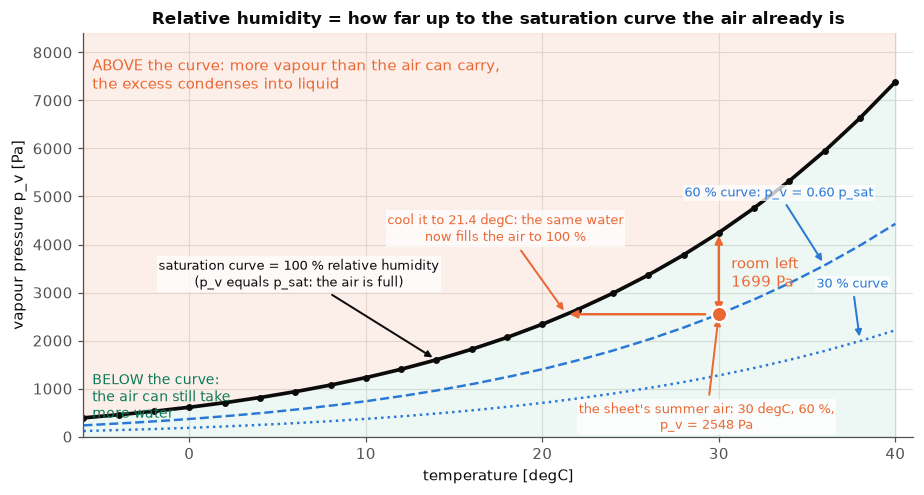

In [3]:
T_TAB = np.arange(-6, 41, 2)
P_TAB = np.array([390.9, 454.9, 527.9, 611.2, 706, 813.5, 935.3, 1073, 1228, 1403, 1599, 1819,
                  2065, 2339, 2645, 2986, 3364, 3783, 4247, 4760, 5325, 5948, 6633, 7385])

def p_sat(t):  return np.interp(t, T_TAB, P_TAB)        # biggest water pressure at temperature t [Pa]
def t_sat(pv): return np.interp(pv, P_TAB, T_TAB)       # reverse look-up: which temperature fills the sponge? (= dew point)
P_ATM = 1e5
def humidity_ratio(pv, p=P_ATM): return 0.622 * pv / (p - pv)         # kg water per kg dry air
def enthalpy(t, x):              return t + x * (2500 + 1.84 * t)      # kJ per kg dry air

tt = np.linspace(-6, 40, 200)
t0 = 30; pv0 = 0.60 * float(p_sat(t0)); td0 = float(t_sat(pv0))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.fill_between(tt, p_sat(tt), 8400, color=ORANGE, alpha=0.10)
ax.fill_between(tt, 0, p_sat(tt), color=AQUA, alpha=0.08)
ax.plot(tt, p_sat(tt), color=INK, lw=2.4); ax.plot(T_TAB, P_TAB, "o", color=INK, ms=3.5)
ax.plot(tt, 0.60 * p_sat(tt), color=BLUE, lw=1.6, ls="--"); ax.plot(tt, 0.30 * p_sat(tt), color=BLUE, lw=1.6, ls=":")
ax.text(-5.5, 7900, "ABOVE the curve: more vapour than the air can carry,\nthe excess condenses into liquid", color=ORANGE, va="top")
ax.text(-5.5, 1350, "BELOW the curve:\nthe air can still take\nmore water", color="#0d7a55", va="top", fontsize=9)
point(ax, (14, float(p_sat(14))), "saturation curve = 100 % relative humidity\n(p_v equals p_sat: the air is full)", (-90, 48), color=INK)
point(ax, (36, 0.60 * float(p_sat(36))), "60 % curve: p_v = 0.60 p_sat", (-30, 45), color=BLUE)
point(ax, (38, 0.30 * float(p_sat(38))), "30 % curve", (-5, 35), color=BLUE)
ax.plot(t0, pv0, "o", color=ORANGE, ms=10, mec="white", mew=1.5, zorder=8)
ax.annotate("", (t0, float(p_sat(t0))), (t0, pv0), arrowprops=dict(arrowstyle="<|-|>", color=ORANGE, lw=1.6))
ax.text(t0 + 0.7, (pv0 + p_sat(t0)) / 2, f"room left\n{p_sat(t0) - pv0:.0f} Pa", color=ORANGE, va="center")
ax.annotate("", (td0, pv0), (t0 - 0.6, pv0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6))
point(ax, (t0, pv0), f"the sheet's summer air: {t0} degC, 60 %,\np_v = {pv0:.0f} Pa", (-8, -75), color=ORANGE)
point(ax, (td0, pv0), f"cool it to {td0:.1f} degC: the same water\nnow fills the air to 100 %", (-40, 48), color=ORANGE)
ax.set_xlabel("temperature [degC]"); ax.set_ylabel("vapour pressure p_v [Pa]"); ax.set_ylim(0, 8400); ax.set_xlim(-6, 41)
ax.set_title("Relative humidity = how far up to the saturation curve the air already is")
plt.tight_layout(); plt.show()

**Reading it.** At 0 °C the air can hold 611 Pa of water, at 30 °C it can hold 4247 Pa, which is about **7 times more**. The orange arrow shows how much room is left in the summer air and the horizontal arrow shows how far it has to cool to be full. Everything else in Part A comes from this picture.

## A3. Summer day vs winter day (the 5 steps of the sheet)

**Summer:** 30 °C and 60 % humidity. **Winter:** 0 °C and 85 % humidity. Both at 1 bar.

1. **Sponge size** $p_{sat}$: look it up in the table.
2. **How much water is really there:** $p_v = \varphi \cdot p_{sat}$ (60 % of the sponge).
3. **Grams of water per kg of dry air, called the humidity ratio $x$:** $x = 0.622\,\dfrac{p_v}{p - p_v}$ (0.622 because water molecules are lighter than air molecules).
4. **Dew point:** find the temperature whose sponge size equals $p_v$ (look the table up **backwards**).
5. **Energy carried, called the enthalpy $h$ (in kJ per kg; a kilojoule is 1000 joules, a unit of energy):** $h = t + x\,(2500 + 1.84\,t)$ (warmth + hidden energy; 2500 kJ/kg is the *latent heat*, what it costs to turn 1 kg of water into vapour, and 1.84 kJ/(kg·K) is how stubborn water vapour is about warming, its *specific heat*, explained below).

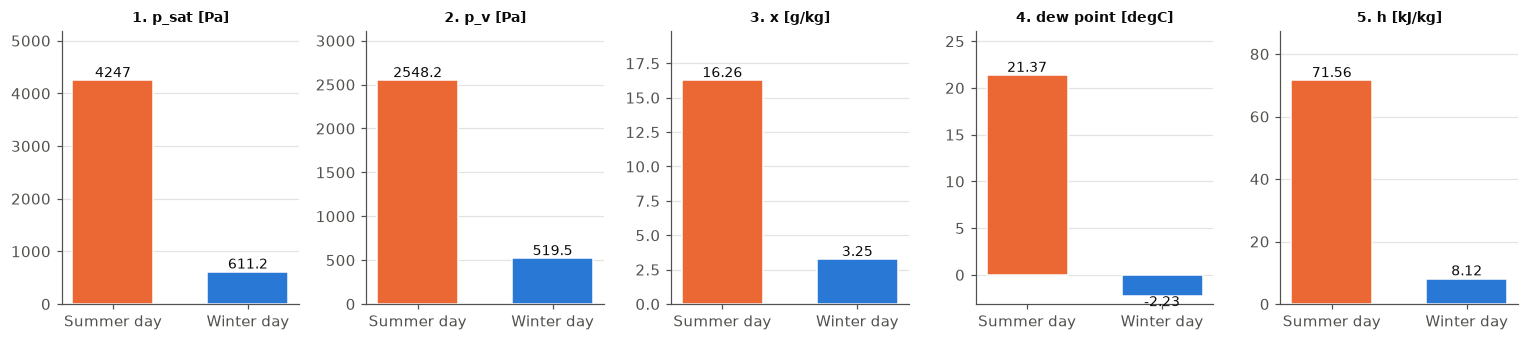

In [4]:
cases = {"Summer day": (30, 0.60), "Winter day": (0, 0.85)}
rows = {}
for name, (t, phi) in cases.items():
    ps = p_sat(t); pv = phi * ps; x = humidity_ratio(pv); tdp = t_sat(pv); h = enthalpy(t, x)
    rows[name] = {"t [degC]": t, "humidity [%]": phi * 100, "1. p_sat [Pa]": round(float(ps), 1),
                  "2. p_v [Pa]": round(float(pv), 1), "3. x [g/kg]": round(1000 * x, 2),
                  "4. dew point [degC]": round(float(tdp), 2), "5. h [kJ/kg]": round(h, 2)}
keys = list(next(iter(rows.values())))[2:]            # the five results of the sheet
fig, axs = plt.subplots(1, len(keys), figsize=(14, 3.2))
for ax, k in zip(axs, keys):
    vals = [rows[n][k] for n in rows]
    ax.bar(list(rows), vals, color=[ORANGE, BLUE], edgecolor="white", width=0.6)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:g}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    ax.set_title(k, fontsize=9); ax.grid(axis="x", visible=False)
    ax.set_ylim(min(0, min(vals) * 1.4), max(vals) * 1.22)
plt.tight_layout(); plt.show()

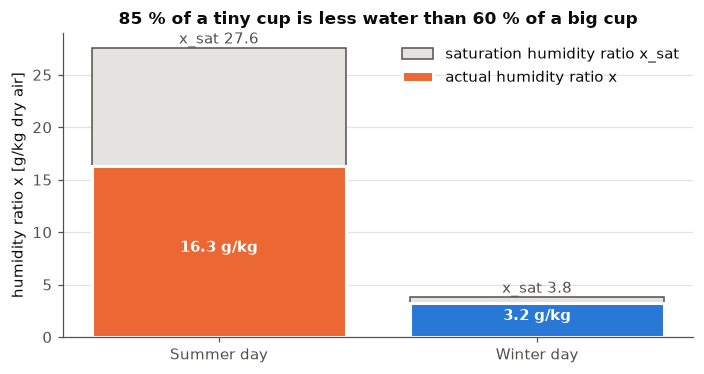

In [5]:
# how much water is in the air (cup filled) vs how much the air COULD hold (the cup's size)
names = list(cases)
now = [1000 * humidity_ratio(phi * p_sat(t)) for t, phi in cases.values()]
cap = [1000 * humidity_ratio(p_sat(t)) for t, phi in cases.values()]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(names, cap, color="#e4e3df", edgecolor=MUTED, label="saturation humidity ratio x_sat")
ax.bar(names, now, color=[SUMMER, WINTER], edgecolor="white", linewidth=2, label="actual humidity ratio x")
for i in range(2):
    ax.text(i, now[i] / 2, f"{now[i]:.1f} g/kg", ha="center", color="white", fontweight="bold")
    ax.text(i, cap[i] + 0.4, f"x_sat {cap[i]:.1f}", ha="center", color=MUTED)
ax.set_ylabel("humidity ratio x [g/kg dry air]"); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("85 % of a tiny cup is less water than 60 % of a big cup")
plt.tight_layout(); plt.show()

**Reading it.** Winter feels "85 % wet", but the cup is tiny, so there are only **3.2 g** of water per kg of air. Summer is "only 60 %" but the cup is huge, so there are **16.3 g**, five times more. **Lesson: the percentage alone lies; the grams tell the truth.**

## Why do we measure water in the air with *pressure* and not in kilograms?

**We use both! They are the same thing said in two ways.**

Imagine a box of tiny bouncing balls (the water molecules). The more balls, the harder they bump the walls of the box. **That bumping is the pressure.** So *more pressure = more water*. Pressure is just a way to count the water without a scale.

The formula that links the two is $p_v = \rho_v \cdot R_v \cdot T$: pressure = (kg of vapour in each m³, the **vapour density** $\rho_v$) × a fixed number × the temperature. And the **humidity ratio** $x$ is just "kg of water ÷ kg of dry air", exactly the number you described:

$$x = \frac{m_{vapour}}{m_{dry\ air}} = 0.622\,\frac{p_v}{p - p_v}$$

**Why use pressure at all?**
- The "sponge is full" rule is written in pressure: the air is full when $p_v = p_{sat}$, so a look-up table does the job. Relative humidity is simply $p_v / p_{sat}$.
- The dew point is also found with that table.

**Why also use kilograms ($x$)?**
- $x$ **does not change** when you only warm up or cool down the air. The water is still the same water! That makes it the honest number for energy and for "how much water do we need to add or remove".
- The percentage (relative humidity) *does* change when you warm the air, as you can see below.

vapour : 18.21 g per m3     dry air: 1.120 kg per m3
x = rho_v/rho_a = 16.26 g/kg      formula 0.622*pv/(p-pv) = 16.26 g/kg   (same thing)


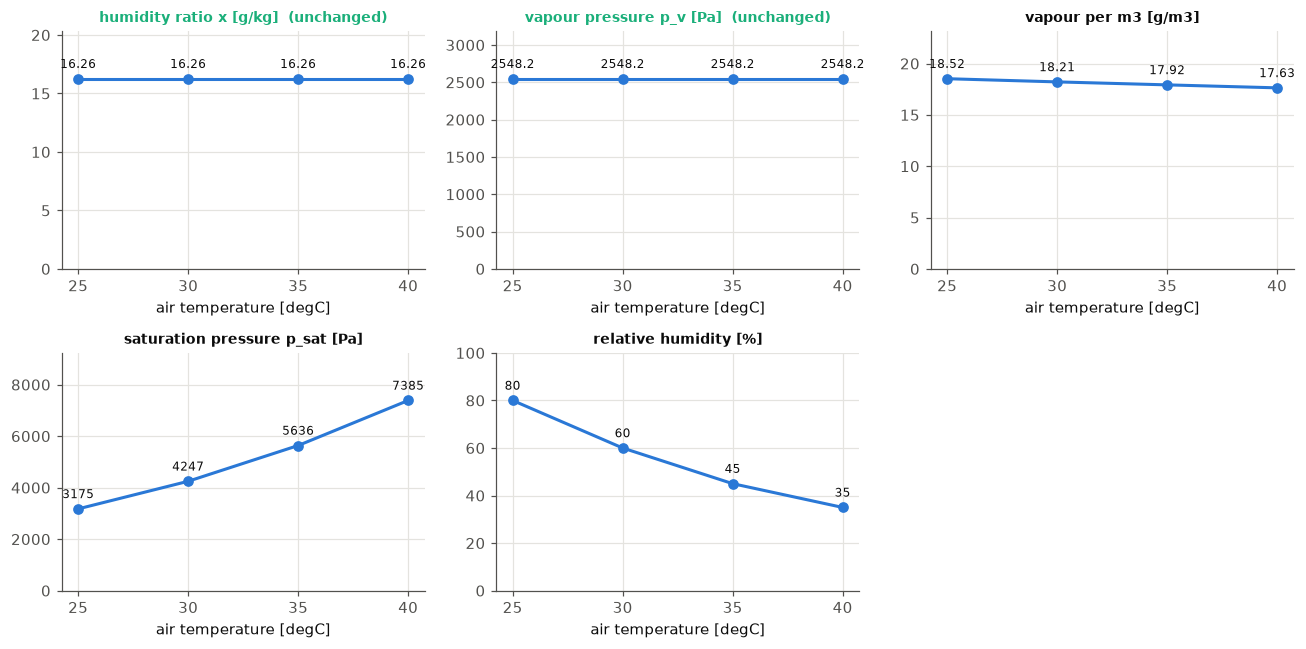

In [6]:
R_a, R_v = 287.0, 461.5            # gas constants [J/(kg.K)]: dry air, water vapour (R_a/R_v = 0.622)
t, phi = 30, 0.60
T = t + 273.15                     # K
pv = phi * p_sat(t)                # Pa, vapour partial pressure
pa = 1e5 - pv                      # Pa, dry-air partial pressure (Dalton: p = pa + pv)
rho_v = pv / (R_v * T)             # kg of vapour per m3   (from pv = rho_v * R_v * T)
rho_a = pa / (R_a * T)             # kg of dry air per m3  (from pa = rho_a * R_a * T)
print(f"vapour : {rho_v*1000:.2f} g per m3     dry air: {rho_a:.3f} kg per m3")
print(f"x = rho_v/rho_a = {1000*rho_v/rho_a:.2f} g/kg      formula 0.622*pv/(p-pv) = {1000*humidity_ratio(pv):.2f} g/kg   (same thing)")

# heat the SAME air (nothing added, nothing removed, total pressure fixed at 1 bar)
rows = []
for tt_ in (25, 30, 35, 40):
    rows.append({"t [degC]": tt_, "x [g/kg]": round(1000 * humidity_ratio(pv), 2), "p_v [Pa]": round(pv, 1),
                 "vapour [g/m3]": round(1000 * pv / (R_v * (tt_ + 273.15)), 2),
                 "p_sat [Pa]": round(float(p_sat(tt_)), 0), "relative humidity [%]": round(100 * pv / float(p_sat(tt_)))})
tt = [r["t [degC]"] for r in rows]
panels = (("x [g/kg]", "humidity ratio x [g/kg]"), ("p_v [Pa]", "vapour pressure p_v [Pa]"), ("vapour [g/m3]", "vapour per m3 [g/m3]"),
          ("p_sat [Pa]", "saturation pressure p_sat [Pa]"), ("relative humidity [%]", "relative humidity [%]"))
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, title) in zip(axs.ravel(), panels):
    vals = [r[k] for r in rows]
    ax.plot(tt, vals, "o-", color=BLUE, lw=2)
    for a, v in zip(tt, vals): ax.annotate(f"{v:g}", (a, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    flat = max(vals) - min(vals) < 1e-9 * max(1, abs(max(vals))) or (max(vals) - min(vals)) / max(vals) < 1e-3
    ax.set_title(title + ("  (unchanged)" if flat else ""), fontsize=9, color=AQUA if flat else INK)
    ax.set_xlabel("air temperature [degC]"); ax.set_xticks(tt); ax.set_ylim(0, max(vals) * 1.25)
axs[1, 2].axis("off")
plt.tight_layout(); plt.show()

**Reading it.** While we warm the same air, the water in it ($x$ in g/kg and $p_v$ in Pa) **stays the same**. But the percentage falls from 80 % (at 25 °C) to 35 % (at 40 °C), because warm air has a bigger sponge. So the percentage is a bit of a trickster; grams per kg (and pressure) tell the truth.

### Heating the air: where does the extra air go?

Here are two sentences that sound like they fight each other:
1. *Warm air spreads out, so a cubic metre has fewer air and water bits in it.*
2. *The grams of water per kg of air ($x$) and the dew point do not change when we only warm the air.*

They don't fight, because **$x$ and the dew point do not count "how many bits per cubic metre"**. $x$ asks: *for each kg of dry air that is here, how much water is mixed in?* Heating doesn't change the mix, only how tightly the bits are packed. What happens to the pressure depends on whether the extra space has anywhere to go.

**A. A real room (it has cracks and gaps).** The warm air spreads out and some of it **leaves through the cracks**. It leaves with the same mix of water and air it had before (look at the dots in the middle picture: 10 grey for every 1 blue, outside and inside). The air that stays has the same mix, so $x$ is the same. The pressure stays at 1 bar, so the water's share of the pressure ($p_v$) stays the same, and so does the dew point. There is less of everything per cubic metre, so the humidity percentage drops (the sponge got bigger).

**B. An isolated room (sealed shut).** Nothing can leave. The same bits are now moving faster and bang into the walls harder, so the **pressure goes up**. This is not magic, it is the gas law $p=\rho R T$: same bits, hotter, more pressure. From 30 °C to 40 °C the pressure goes up by 3.3 % (1 bar becomes 1.033 bar; a closed bottle left in the sun can burst). The water's share of the pressure goes up by the same 3.3 %, so $p_v$ goes from 2548 to 2632 Pa. The grams of water per kg of air ($x$) is exactly the same, but the dew point rises a little, **from 21.4 °C to 21.9 °C**, because the water pushes harder.

The first picture shows the three rooms (with extra dots so you can see them), the second compares the numbers.

![Heating a room: the water stays, so only the percentage drops](../images/sealed-vs-leaky-room.svg)

*Figure: Heating a room: the water stays, so only the percentage drops*

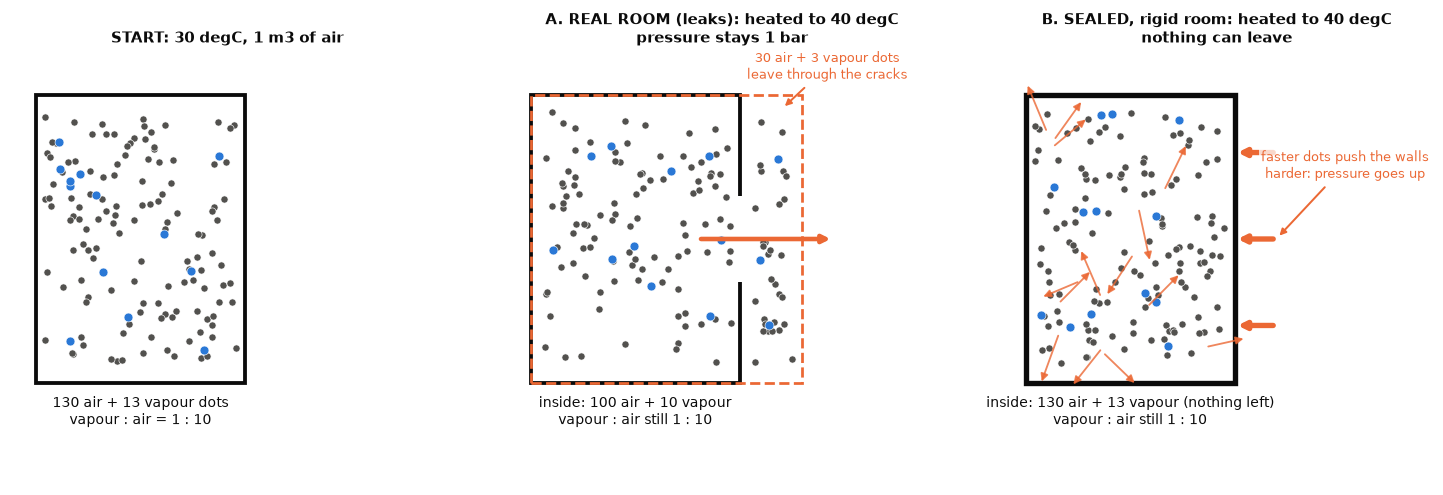

In [7]:
# schematic of one room (30 degC -> 40 degC). Numbers of dots are exaggerated for visibility: vapour = blue, dry air = grey
rng = np.random.default_rng(7)
N_AIR, N_VAP, GROW = 130, 13, 1.30            # a real 30 -> 40 degC step only expands the air by 3.3 %; drawn as 30 % so it is visible
def scatter_in(ax, n, x0, x1, color, size=22):
    ax.scatter(rng.uniform(x0 + 0.04, x1 - 0.04, n), rng.uniform(0.06, 0.94, n), s=size, color=color, edgecolor="white", lw=0.4, zorder=3)
def room(ax, w=1.0, ls="-", color=INK, lw=2.5):
    ax.add_patch(plt.Rectangle((0, 0), w, 1, fill=False, ec=color, lw=lw, ls=ls, zorder=2))
def speed(ax, n, length, color):
    px, py = rng.uniform(0.1, 0.9, n), rng.uniform(0.1, 0.9, n); ang = rng.uniform(0, 2 * np.pi, n)
    for a, b, t in zip(px, py, ang):
        ax.annotate("", (a + length * np.cos(t), b + length * np.sin(t)), (a, b), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2, alpha=0.8), zorder=4)

fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.6))
for ax in axs: ax.set_xlim(-0.12, 1.95); ax.set_ylim(-0.35, 1.15); ax.axis("off")

ax = axs[0]; room(ax); scatter_in(ax, N_AIR, 0, 1, MUTED); scatter_in(ax, N_VAP, 0, 1, BLUE, 34)
ax.set_title("START: 30 degC, 1 m3 of air", fontsize=10)
ax.text(0.5, -0.04, f"{N_AIR} air + {N_VAP} vapour dots\nvapour : air = 1 : 10", ha="center", va="top", fontsize=9)

ax = axs[1]; room(ax); room(ax, GROW, ls="--", color=ORANGE, lw=1.8)            # dashed = where the heated air would like to be
keep = int(N_AIR / GROW); keepv = int(round(N_VAP / GROW))
scatter_in(ax, keep, 0, 1, MUTED); scatter_in(ax, keepv, 0, 1, BLUE, 34)
scatter_in(ax, N_AIR - keep, 1.02, GROW, MUTED); scatter_in(ax, N_VAP - keepv, 1.02, GROW, BLUE, 34)
ax.add_patch(plt.Rectangle((0.985, 0.35), 0.05, 0.3, fc="white", ec="none", zorder=5)); ax.annotate("", (1.45, 0.5), (0.8, 0.5), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3), zorder=6)
point(ax, (1.2, 0.95), f"{N_AIR - keep} air + {N_VAP - keepv} vapour dots\nleave through the cracks", (30, 20), color=ORANGE)
ax.set_title("A. REAL ROOM (leaks): heated to 40 degC\npressure stays 1 bar", fontsize=10)
ax.text(0.5, -0.04, f"inside: {keep} air + {keepv} vapour\nvapour : air still 1 : 10", ha="center", va="top", fontsize=9)

ax = axs[2]; room(ax, lw=3.5, color=INK); scatter_in(ax, N_AIR, 0, 1, MUTED); scatter_in(ax, N_VAP, 0, 1, BLUE, 34)
speed(ax, 14, 0.2, ORANGE)
for yy in (0.2, 0.5, 0.8):
    ax.annotate("", (1.0, yy), (1.2, yy), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3.5));
point(ax, (1.2, 0.5), "faster dots push the walls\nharder: pressure goes up", (45, 40), color=ORANGE)
ax.set_title("B. SEALED, rigid room: heated to 40 degC\nnothing can leave", fontsize=10)
ax.text(0.5, -0.04, f"inside: {N_AIR} air + {N_VAP} vapour (nothing left)\nvapour : air still 1 : 10", ha="center", va="top", fontsize=9)
plt.tight_layout(); plt.show()

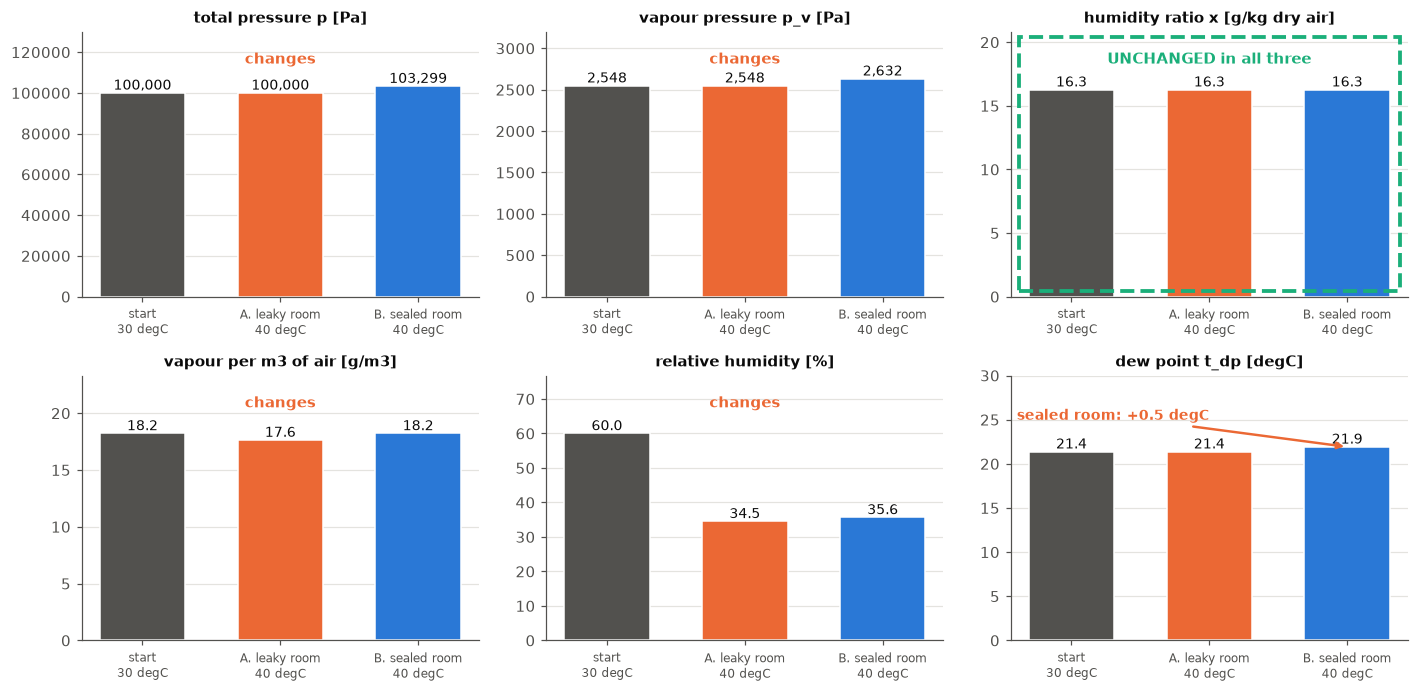

In [8]:
# the same story in numbers: start 30 degC / 60 % / 1 bar, then heated to 40 degC
R_v = 461.5
t_start, t_end2 = 30.0, 40.0; k_ratio = (t_end2 + 273.15) / (t_start + 273.15)
pv_start = 0.60 * float(p_sat(t_start)); p_start = 1e5
cases3 = {"start\n30 degC": (pv_start, p_start, t_start), "A. leaky room\n40 degC": (pv_start, p_start, t_end2), "B. sealed room\n40 degC": (pv_start * k_ratio, p_start * k_ratio, t_end2)}
rows3 = {"total pressure p [Pa]": [], "vapour pressure p_v [Pa]": [], "humidity ratio x [g/kg dry air]": [], "vapour per m3 of air [g/m3]": [],
        "relative humidity [%]": [], "dew point t_dp [degC]": []}
for pv, p, t in cases3.values():
    rows3["total pressure p [Pa]"].append(p); rows3["vapour pressure p_v [Pa]"].append(pv); rows3["humidity ratio x [g/kg dry air]"].append(1000 * humidity_ratio(pv, p))
    rows3["vapour per m3 of air [g/m3]"].append(1000 * pv / (R_v * (t + 273.15)) if p == p_start else 1000 * pv_start / (R_v * (t_start + 273.15)))   # sealed: same mass in the same m3
    rows3["relative humidity [%]"].append(100 * pv / float(p_sat(t))); rows3["dew point t_dp [degC]"].append(float(t_sat(pv)))
labels3 = list(cases3); cols3 = [MUTED, ORANGE, BLUE]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, (title, vals) in zip(axs.ravel(), rows3.items()):
    b = ax.bar(range(3), vals, color=cols3, edgecolor="white", width=0.62)
    lo, hi = min(vals), max(vals); same = (hi - lo) / hi < 1e-3
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.1f}" if v < 1000 else f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels3, fontsize=8); ax.set_title(title, fontsize=10)
    ax.set_ylim(0, hi * 1.28); ax.grid(axis="x", visible=False)
    if same:
        ax.text(0.5, 0.88, "UNCHANGED in all three", transform=ax.transAxes, ha="center", color=AQUA, fontweight="bold", fontsize=10)
        ax.add_patch(plt.Rectangle((0.02, 0.02), 0.96, 0.96, transform=ax.transAxes, fill=False, ec=AQUA, lw=2.5, ls="--"))
    elif title.startswith("dew point"):
        ax.annotate(f"sealed room: +{vals[2] - vals[0]:.1f} degC", (2, vals[2]), xytext=(0.3, hi * 1.14), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6), color=ORANGE, fontweight="bold", fontsize=9, ha="center")
    else:
        ax.text(0.5, 0.88, "changes", transform=ax.transAxes, ha="center", color=ORANGE, fontweight="bold", fontsize=10)
axs[0, 0].set_ylim(0, 1.3e5); axs[0, 1].set_ylim(0, 3200); axs[1, 2].set_ylim(0, 30)
plt.tight_layout(); plt.show()


## A4. Dew point: when the sponge gets full

Imagine the air in the summer day getting cooled down **without adding or removing water**. The amount of water stays the same ($p_v$ is a straight line in the chart), but the sponge gets smaller (the black 100 % curve comes down towards it). At some temperature the sponge is exactly full, 100 %. That is the **dew point**. Cooler than that, water drops out (fog, dew, a wet cold glass).

**The dew point as a formula.** The dew point is the temperature where the sponge size ($p_{sat}$) is exactly the amount of water in the air ($p_v$):

$$p_{sat}(t_{dp}) = p_v$$

So we use the sponge-size table **backwards**: we start from the water amount $p_v$ and read off a temperature. The sheet's Antoine equation (a formula fitted to measured values), $p_{sat}(t)=e^{16.6536-4030.183/(t+235)}$ in kPa, can also be solved for the temperature:

$$t_{dp}=\frac{4030.183}{16.6536-\ln p_v}-235\qquad(p_v\text{ in kPa})$$

If you only know the air temperature and the humidity percentage, first find $p_v=\varphi\cdot p_{sat}(t)$, then use the formula.

**Why the dew point doesn't care about the air temperature.** "Sponge size" means two things:
- the **table** of sponge sizes for every temperature, which is a fixed fact about water;
- the sponge size **right now** at the air's temperature, one line of that table.

The dew point reads the table backwards starting from $p_v$, so it never uses the air's own temperature. Warm the air without adding water: the sponge right now gets bigger (the percentage drops), but the water amount and the table stay the same, so the dew point stays the same. It only moves when the water amount moves: more evaporation raises it, condensation (vapour turning into drops, explained below) lowers it, and a sealed room that is heated raises it a little (see the section on heating the air above). More water in the air always means a higher dew point.

![Cooling humid air: nothing happens until it is full, then drops appear](../images/humidity-ratio-and-dew-point.svg)

*Figure: Cooling humid air: nothing happens until it is full, then drops appear*

![The air map: up is more water, right is warmer](../images/psychrometric-chart.svg)

*Figure: The air map: up is more water, right is warmer*

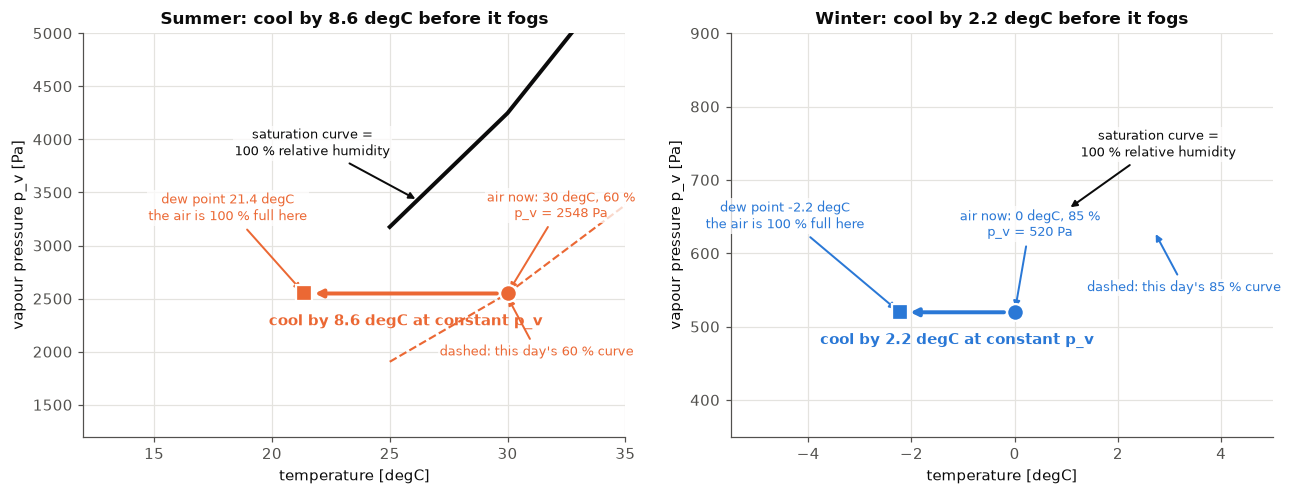

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
zoom = {"Summer": ((12, 35), (1200, 5000), (-50, 48), (-70, 30)), "Winter": ((-5.5, 5), (350, 900), (-75, 55), (60, 35))}
for ax, (name, (t, phi)), col in zip(axs, (("Summer", cases["Summer day"]), ("Winter", cases["Winter day"])), (SUMMER, WINTER)):
    (x0, x1), (y0, y1), off_dp, off_curve = zoom[name]
    pv = phi * p_sat(t); tdp = float(t_sat(pv))
    ax.plot(tt, p_sat(tt), color=INK, lw=2.6)
    ax.plot(tt, phi * p_sat(tt), color=col, lw=1.4, ls="--")                                     # curve of constant relative humidity
    ax.annotate("", (tdp, pv), (t, pv), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.6, shrinkA=7, shrinkB=7))   # cooling at constant p_v
    ax.plot(t, pv, "o", color=col, ms=11, mec="white", mew=1.5, zorder=8)                        # current state
    ax.plot(tdp, pv, "s", color=col, ms=10, mec="white", mew=1.5, zorder=8)                      # dew point, on the 100 % curve
    ax.text((t + tdp) / 2, pv - 0.05 * (y1 - y0), f"cool by {t - tdp:.1f} degC at constant p_v", ha="center", va="top", color=col, fontweight="bold")
    point(ax, (t, pv), f"air now: {t} degC, {phi*100:.0f} %\np_v = {pv:.0f} Pa", (35 if name == "Summer" else 10, 50), color=col)
    point(ax, (tdp, pv), f"dew point {tdp:.1f} degC\nthe air is 100 % full here", off_dp, color=col)
    xc = x0 + 0.62 * (x1 - x0)
    point(ax, (xc, float(p_sat(xc))), "saturation curve =\n100 % relative humidity", off_curve, color=INK)
    xd = x0 + 0.78 * (x1 - x0)
    point(ax, (xd, phi * float(p_sat(xd))), f"dashed: this day's {phi*100:.0f} % curve", (20, -40), color=col)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_xlabel("temperature [degC]"); ax.set_ylabel("vapour pressure p_v [Pa]")
    ax.set_title(f"{name}: cool by {t - tdp:.1f} degC before it fogs")
plt.tight_layout(); plt.show()

**Reading it.** Circle = the air now. Square = its dew point, always sitting **on the black 100 % curve**. The arrow is the cooling. In summer the air needs to cool **8.6 °C** (to 21.4 °C) before drops form, so a cold wall or an air-conditioner pipe at 15 °C will **drip**. In winter only 2.2 °C below zero is needed, so you get frost on a cold window. The winter arrow is short even though 85 % sounds wetter than 60 %: the winter sponge is small.

## What is condensation?

**Condensation is when invisible water in the air turns into tiny drops of liquid water.**

You have seen it:
- the drops on the **outside of a cold glass** of lemonade,
- the **mirror fogging up** after a hot shower,
- **dew** on the grass in the morning, **fog** and **clouds**,
- water on a **window** on a cold day.

**Why it happens:** remember the sponge. Cold air has a *small* sponge. If air touches something cold, its sponge shrinks until it can't hold all its water any more. The extra water **squeezes out as drops**. The temperature where this starts is the **dew point**.

- Surface **warmer** than the dew point → stays dry.
- Surface **colder** than the dew point → drops appear.

When water turns from vapour into liquid it **gives out heat** (the hidden energy from before). An air conditioner works like a cold glass: it makes water drip out of the air, which both cools **and dries** the room.

**Two "water in the air" numbers appear in the chart below, and they are different.**
- **The water the air really has ($x$, orange flat line).** If nobody adds or removes water, it **doesn't change when the temperature changes**.
- **The most water the air could hold ($x_{sat}(t)$, blue curve).** This is the size of the sponge at each temperature, written in grams per kg of air, so it **does change with temperature**: warm air has a big sponge, cold air a small one. It is the 100 % line of A2 again, not a measure of the water that is there.

Cooling the air moves it **left along the flat line** (same water) until the line touches the curve: the dew point, the sponge is full. Cooling further, the sponge becomes smaller than the water inside, so the extra water **squeezes out as drops** and the air's own water now goes down along the curve. **The air's water only changes with temperature after the drops start.**

At 15 degC the air can hold only 10.81 g/kg, it carries 16.26 g/kg
-> 5.45 g of every kg turns to liquid; for the room's 84.14 kg of air that is 459 g of water
-> condensing releases 13.6 kJ per kg of air, 1146 kJ in the room


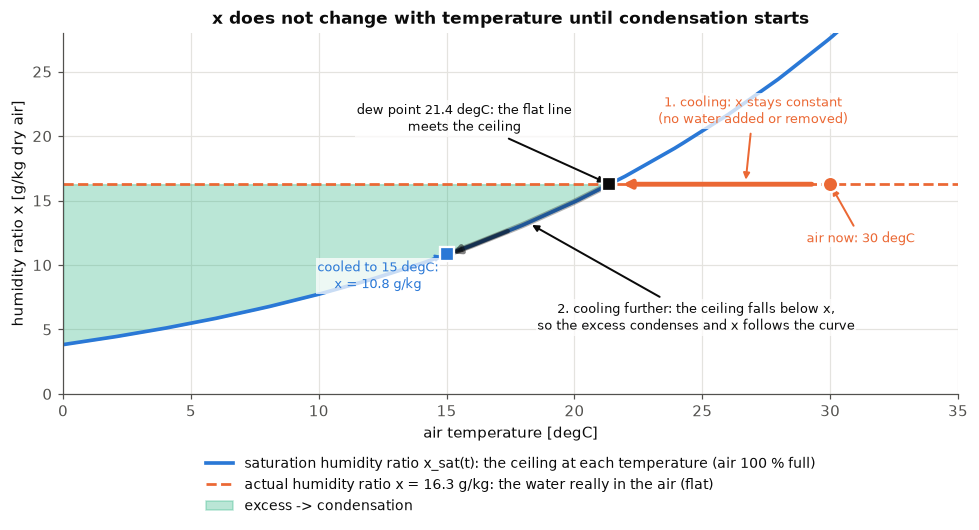

In [10]:
t0, phi0, t_end = 30, 0.60, 15
x_now = 1000 * humidity_ratio(phi0 * p_sat(t0))          # g/kg, what the air carries
x_end = 1000 * humidity_ratio(p_sat(t_end))              # g/kg, the most air at 15 degC can carry
drop = x_now - x_end                                     # g of liquid per kg of dry air
room_air = 84.14                                         # kg, the air mass of the 6x4x3 m room (A1)
print(f"At {t_end} degC the air can hold only {x_end:.2f} g/kg, it carries {x_now:.2f} g/kg")
print(f"-> {drop:.2f} g of every kg turns to liquid; for the room's {room_air} kg of air that is {drop*room_air:.0f} g of water")
print(f"-> condensing releases {drop/1000*2500:.1f} kJ per kg of air, {drop/1000*2500*room_air:.0f} kJ in the room")

tt2 = np.linspace(0, 35, 200)
x_sat = 1000 * humidity_ratio(p_sat(tt2))
td = float(t_sat(phi0 * p_sat(t0)))                      # dew point: where the flat line meets the curve
xs = lambda t: 1000 * humidity_ratio(p_sat(t))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tt2, x_sat, color=BLUE, lw=2.4, label="saturation humidity ratio x_sat(t): the ceiling at each temperature (air 100 % full)")
ax.axhline(x_now, color=ORANGE, ls="--", lw=1.8, label=f"actual humidity ratio x = {x_now:.1f} g/kg: the water really in the air (flat)")
ax.fill_between(tt2, x_sat, x_now, where=x_sat < x_now, color=AQUA, alpha=0.3, label="excess -> condensation")
ax.annotate("", (td + 0.4, x_now), (t0 - 0.6, x_now), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=3.2))          # stage 1: x constant
tc = np.linspace(td, t_end, 40); ax.plot(tc, xs(tc), color=INK, lw=4, alpha=0.3)                                         # stage 2: follows the curve
ax.annotate("", (t_end + 0.1, xs(t_end)), (t_end + 2.5, xs(t_end + 2.5)), arrowprops=dict(arrowstyle="-|>", color=INK, lw=3, alpha=0.5))
ax.plot(t0, x_now, "o", color=ORANGE, ms=10, mec="white", mew=1.5, zorder=8); ax.plot(td, x_now, "s", color=INK, ms=9, mec="white", mew=1.5, zorder=8)
ax.plot(t_end, x_end, "s", color=BLUE, ms=9, mec="white", mew=1.5, zorder=8)
point(ax, (t0, x_now), f"air now: {t0} degC", (20, -38), color=ORANGE)
point(ax, ((t0 + td) / 2 + 1, x_now), "1. cooling: x stays constant\n(no water added or removed)", (5, 40), color=ORANGE)
point(ax, (td, x_now), f"dew point {td:.1f} degC: the flat line\nmeets the ceiling", (-95, 35), color=INK)
point(ax, ((td + t_end) / 2, xs((td + t_end) / 2)), "2. cooling further: the ceiling falls below x,\nso the excess condenses and x follows the curve", (110, -70), color=INK)
point(ax, (t_end, x_end), f"cooled to {t_end} degC:\nx = {x_end:.1f} g/kg", (-45, -22), color=BLUE)
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("humidity ratio x [g/kg dry air]"); ax.set_ylim(0, 28); ax.set_xlim(0, 35)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)
ax.set_title("x does not change with temperature until condensation starts")
plt.tight_layout(); plt.show()

**Reading it.** Summer air (30 °C, 60 %) has a dew point of 21.4 °C. If it touches something at 15 °C, its sponge only holds 10.8 g per kg instead of 16.3 g, so about 5.5 g per kg turns into drops. For all the air in the room that is about **half a litre of water**, a small bottle! The green area on the chart is the water that has to leave the air. The flat orange line is the water the air really has (it stays the same while cooling), the blue curve is the sponge size at each temperature, and the two arrows are the two stages: along the flat line to the dew point, then along the curve while drops form.

## What is specific heat?

**Specific heat tells you how "stubborn" a material is about getting warm.**

It is the energy needed to warm **1 kg** of something by **1 degree**. Think of two pots on a stove: one with a little oil and one with the same weight of water. The oil gets hot much faster. Water is "stubborn": it needs a lot of energy for every degree, so it also stays warm for a long time.

$$\text{energy} = \text{mass}\times\text{specific heat}\times\text{temperature change}$$

- **Dry air**: **1.0** (exactly 1.006) — warms up easily
- **Water vapour**: **1.84** — in between
- **Liquid water**: **4.19** — very stubborn

**Where do we use it?** In the **energy of the air** $h$:

$$h = \underbrace{1\cdot t}_{\text{warmth of the dry air}} + x\Big(\underbrace{2500}_{\text{energy to make vapour}} + \underbrace{1.84\cdot t}_{\text{warmth of the vapour}}\Big)$$

The "1" is the specific heat of dry air, the "1.84" the specific heat of vapour. The 2500 is **not** a specific heat: it is the big chunk of energy needed to turn 1 kg of liquid water into vapour (even without getting any warmer).

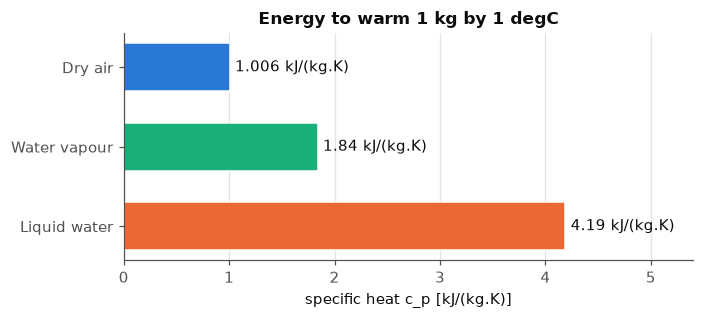

In [11]:
mats = {"Dry air": 1.006, "Water vapour": 1.84, "Liquid water": 4.19}
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(list(mats), list(mats.values()), color=[BLUE, AQUA, ORANGE], edgecolor="white", height=0.6)
for i, v in enumerate(mats.values()): ax.text(v + 0.05, i, f"{v} kJ/(kg.K)", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 5.4); ax.set_xlabel("specific heat c_p [kJ/(kg.K)]"); ax.grid(axis="y", visible=False)
ax.set_title("Energy to warm 1 kg by 1 degC")
plt.tight_layout(); plt.show()

![Water needs about 4 times more energy than air to warm up by one degree](../images/specific-heat.svg)

*Figure: Water needs about 4 times more energy than air to warm up by one degree*

In [12]:
c_pa, c_pv, c_w = 1.006, 1.84, 4.19                  # specific heats [kJ/(kg.K)]: dry air, vapour, liquid water
m_room = 84.14                                       # kg of air in the 6x4x3 m room
print(f"warm the room's air by 1 K : {m_room*c_pa:6.1f} kJ")
print(f"warm the same MASS of water: {m_room*c_w:6.1f} kJ   ({c_w/c_pa:.1f} times more)")

x = humidity_ratio(0.60 * p_sat(30)); t = 30          # summer day
air_part = t                                          # sheet: c_pa taken as 1 -> 1*t
vap_part = x * 1.84 * t                               # sensible heat of the vapour
latent = x * 2500                                     # evaporation energy
print(f"h = {air_part:.2f} (dry air) + {vap_part:.2f} (vapour warmth) + {latent:.2f} (latent) = {air_part+vap_part+latent:.2f} kJ/kg")
print(f"with c_pa = 1.006 instead of 1: h = {c_pa*t+vap_part+latent:.2f} kJ/kg (difference {100*(c_pa-1)*t/(air_part+vap_part+latent):.2f} %)")

warm the room's air by 1 K :   84.6 kJ
warm the same MASS of water:  352.5 kJ   (4.2 times more)
h = 30.00 (dry air) + 0.90 (vapour warmth) + 40.66 (latent) = 71.56 kJ/kg
with c_pa = 1.006 instead of 1: h = 71.74 kJ/kg (difference 0.25 %)


**Reading it.** Warming the air in the room by one degree takes about 85 kJ, but warming the same weight of water takes more than 350 kJ, about 4 times more. In the summer air's 71.6 kJ/kg: 30 is the warmth of the dry air, 0.9 the warmth of the water vapour and 40.7 the hidden energy. Using 1.006 instead of 1 changes the answer by a tiny 0.25 %, so the sheet just uses 1.

## A5. Enthalpy: the energy you can't feel

$h = \underbrace{t}_{\text{warmth (sensible)}} + \underbrace{x\,(2500 + 1.84\,t)}_{\text{hidden in water (latent)}}$

Think of **two piggy banks**: one holds the warmth you can feel with a thermometer, the other holds energy hidden in the water. An air conditioner has to empty **both**.

![Hot air carries two kinds of energy: warmth you feel and energy hidden in water](../images/enthalpy.svg)

*Figure: Hot air carries two kinds of energy: warmth you feel and energy hidden in water*

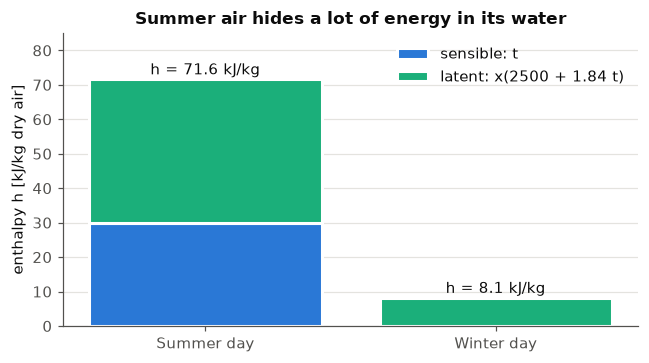

In [13]:
sens = [t for t, phi in cases.values()]
lat = [humidity_ratio(phi * p_sat(t)) * (2500 + 1.84 * t) for t, phi in cases.values()]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(names, sens, color=BLUE, edgecolor="white", linewidth=2, label="sensible: t")
ax.bar(names, lat, bottom=sens, color=AQUA, edgecolor="white", linewidth=2, label="latent: x(2500 + 1.84 t)")
for i in range(2): ax.text(i, sens[i] + lat[i] + 1.5, f"h = {sens[i] + lat[i]:.1f} kJ/kg", ha="center")
ax.set_ylabel("enthalpy h [kJ/kg dry air]"); ax.set_ylim(0, 85); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("Summer air hides a lot of energy in its water")
plt.tight_layout(); plt.show()

**Reading it.** In summer, 42 of the 71.6 kJ/kg are hidden in the water, so cooling alone is not enough: you must also **dry** the air. In winter (0 °C) there is no warmth to count, so the whole 8.1 kJ/kg is hidden energy.

## A6. The whole day

The sheet gives 24 hourly temperatures and humidities (Bucharest, 8 August and 1 February). We repeat the 5 steps for every hour and plot the **grams of water per kg of air**.

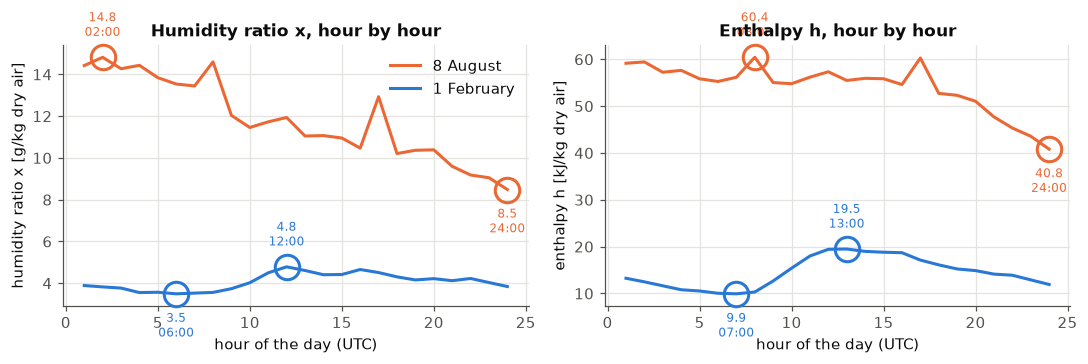

Summer: water 8.5-14.8 g/kg, energy 41-60 kJ/kg
Winter: water 3.5-4.8 g/kg, energy 10-19 kJ/kg


In [14]:
hours = np.arange(1, 25)
t_s = np.array([22.5, 21.8, 21, 21, 20.7, 20.9, 22, 23.3, 24.4, 25.6, 26.3, 26.9, 27.3, 27.7, 27.9, 27.9, 27.3, 26.7, 25.9, 24.6, 23.3, 22, 20.6, 19.3])
f_s = np.array([83, 89, 90, 91, 89, 86, 80, 80, 62, 55, 54, 53, 48, 47, 46, 44, 56, 46, 49, 53, 53, 55, 59, 60])
t_w = np.array([3.5, 2.9, 2.2, 1.9, 1.6, 1.3, 1.1, 1.4, 3.3, 5.3, 6.7, 7.4, 7.9, 7.9, 7.7, 7, 5.8, 5.3, 4.8, 4.3, 3.8, 3.3, 2.8, 2.3])
f_w = np.array([79, 81, 84, 81, 83, 83, 85, 84, 77, 72, 73, 74, 69, 66, 67, 74, 78, 77, 77, 81, 82, 87, 86, 85])

def day(t, phi):
    pv = phi / 100 * p_sat(t); x = humidity_ratio(pv)
    return 1000 * x, enthalpy(t, x)
xs, hs = day(t_s, f_s); xw, hw = day(t_w, f_w)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].plot(hours, xs, color=SUMMER, lw=2, label="8 August"); axs[0].plot(hours, xw, color=WINTER, lw=2, label="1 February")
axs[0].set_ylabel("humidity ratio x [g/kg dry air]"); axs[0].set_title("Humidity ratio x, hour by hour")
axs[1].plot(hours, hs, color=SUMMER, lw=2); axs[1].plot(hours, hw, color=WINTER, lw=2)
axs[1].set_ylabel("enthalpy h [kJ/kg dry air]"); axs[1].set_title("Enthalpy h, hour by hour")
for a in axs: a.set_xlabel("hour of the day (UTC)")
axs[0].legend(frameon=False)
for ax_, arr_, col_ in ((axs[0], xs, SUMMER), (axs[0], xw, WINTER), (axs[1], hs, SUMMER), (axs[1], hw, WINTER)):
    for i_ in (int(np.argmax(arr_)), int(np.argmin(arr_))):
        ring(ax_, hours[i_], arr_[i_], color=col_, size=16)
        ax_.annotate(f"{arr_[i_]:.1f}\n{hours[i_]:02d}:00", (hours[i_], arr_[i_]), xytext=(0, 14 if i_ == int(np.argmax(arr_)) else -28), textcoords="offset points", ha="center", fontsize=8, color=col_)
plt.tight_layout(); plt.show()
print(f"Summer: water {xs.min():.1f}-{xs.max():.1f} g/kg, energy {hs.min():.0f}-{hs.max():.0f} kJ/kg")
print(f"Winter: water {xw.min():.1f}-{xw.max():.1f} g/kg, energy {hw.min():.0f}-{hw.max():.0f} kJ/kg")

**Reading it.** The rings mark the highest and lowest points of each line. The summer air always carries much more water and energy than the winter air (roughly 3 to 4 times as much energy). That is why summer needs air-conditioning that **cools and dries**, while winter needs **heating** (and sometimes adding humidity). Notice that the summer energy peaks at 08:00, when the air is already warm and still very humid, and not at the hottest hour: section A7 explains why.

## A7. Which curves move together?

All the graphs above show the **same few things**, and they are linked, because most of them are **calculated from each other**. Only the air temperature $t$ and the humidity percentage $\varphi$ are measured. Here we look at the 24 hours of both days and check, one pair at a time, which curves rise and fall together, which are opposites and why.

**The "friendship score" (correlation, $r$).** A number from −1 to +1:
- **+1** = they rise and fall **together** (left plot: dots go up from left to right);
- **0** = **strangers**, no pattern (middle plot);
- **−1** = **opposites**, like a seesaw (right plot: dots go down).

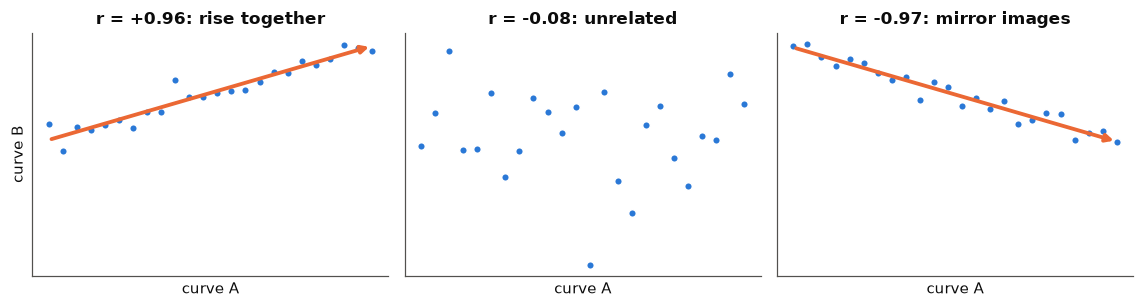

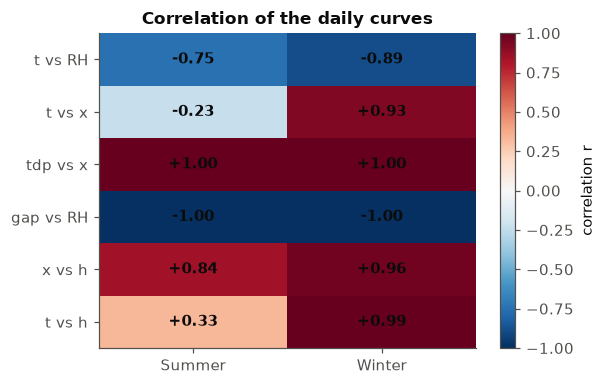

In [15]:
def daily(t, phi):
    pv = phi / 100 * p_sat(t); x = 1000 * humidity_ratio(pv); tdp = t_sat(pv)
    return dict(t=t, RH=phi, x=x, tdp=tdp, gap=t - tdp, h=enthalpy(t, x / 1000))
DAYS = {"Summer": (daily(t_s, f_s), SUMMER), "Winter": (daily(t_w, f_w), WINTER)}
corr = lambda d, a, b: np.corrcoef(d[a], d[b])[0, 1]

# what a correlation looks like: three toy pairs of curves
rng = np.random.default_rng(3); u = np.linspace(0, 1, 24)
toy = [("rise together", 2 * u + 0.15 * rng.normal(size=24)), ("unrelated", rng.normal(size=24)), ("mirror images", 2 - 2 * u + 0.15 * rng.normal(size=24))]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 2.9), sharex=True, sharey=True)
for ax, (name, y) in zip(axs, toy):
    r = np.corrcoef(u, y)[0, 1]; k = np.polyfit(u, y, 1)
    ax.plot(u, y, "o", color=BLUE, ms=5, mec="white")
    if abs(r) > 0.5:
        ax.annotate("", (1, np.polyval(k, 1)), (0, np.polyval(k, 0)), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
    ax.set_title(f"r = {r:+.2f}: {name}"); ax.set_xlabel("curve A"); ax.set_xticks([]); ax.set_yticks([])
axs[0].set_ylabel("curve B")
plt.tight_layout(); plt.show()

pairs = [("t", "RH"), ("t", "x"), ("tdp", "x"), ("gap", "RH"), ("x", "h"), ("t", "h")]
names = list(DAYS)
M = np.array([[corr(d, a, b) for n, (d, _) in DAYS.items()] for a, b in pairs])
fig, ax = plt.subplots(figsize=(5.6, 3.6))
im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.set_yticks(range(len(pairs))); ax.set_yticklabels([f"{a} vs {b}" for a, b in pairs])
for i in range(len(pairs)):
    for j in range(len(names)):
        ax.text(j, i, f"{M[i, j]:+.2f}", ha="center", va="center", fontsize=10, fontweight="bold")
ax.grid(False); ax.set_title("Correlation of the daily curves")
fig.colorbar(im, ax=ax, label="correlation r"); plt.tight_layout(); plt.show()

**Map of who is calculated from whom** (an arrow means "is calculated from"):
1. **The water amount.** From $t$ and $\varphi$ we get $p_v$, and from $p_v$ alone we get **both** $x$ and the dew point. So $x$ and the dew point are the same information (one in g/kg, one in °C): they must have the same shape (section 3).
2. **The percentage.** $\varphi=p_v/p_{sat}(t)$ uses the temperature again. Warmer air has a bigger sponge, so with the same water the percentage goes **down** (section 2). The gap $t-t_{dp}$ says the same thing in degrees (section 4).
3. **The energy.** $h$ adds the warmth ($t$) and the hidden energy (from $x$), so it follows whichever moves more (section 5).

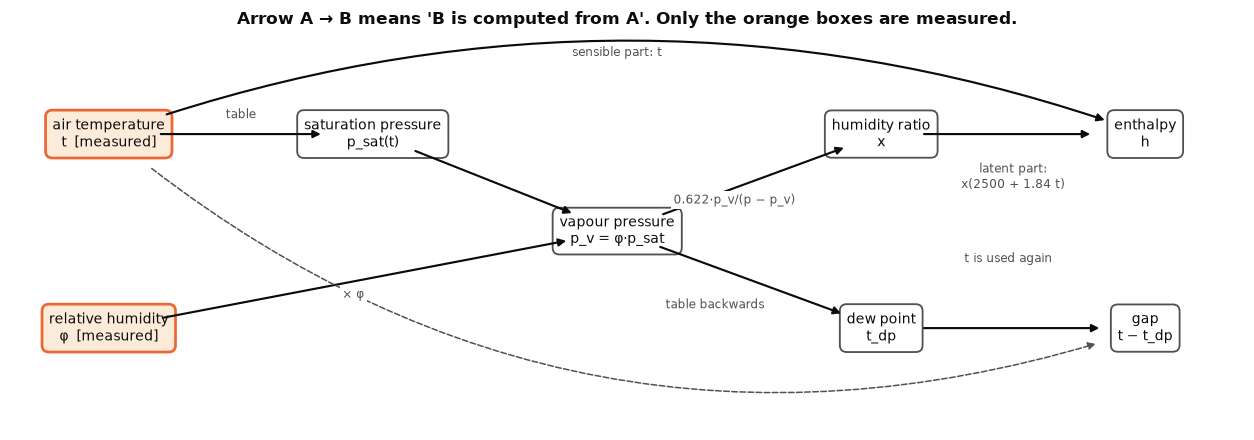

In [16]:
fig, ax = plt.subplots(figsize=(11.5, 4.1)); ax.set_xlim(0, 12.6); ax.set_ylim(-0.4, 4.7); ax.axis("off")
pos = {"t": (1.0, 3.4), "phi": (1.0, 0.9), "psat": (3.7, 3.4), "pv": (6.2, 2.15), "x": (8.9, 3.4), "tdp": (8.9, 0.9), "h": (11.6, 3.4), "gap": (11.6, 0.9)}
txt = {"t": "air temperature\nt  [measured]", "phi": "relative humidity\nφ  [measured]", "psat": "saturation pressure\np_sat(t)", "pv": "vapour pressure\np_v = φ·p_sat", "x": "humidity ratio\nx", "tdp": "dew point\nt_dp", "h": "enthalpy\nh", "gap": "gap\nt − t_dp"}
for k, (px, py) in pos.items():
    given = k in ("t", "phi")
    ax.text(px, py, txt[k], ha="center", va="center", fontsize=9, zorder=3,
            bbox=dict(boxstyle="round,pad=0.5", fc="#fdebd9" if given else "white", ec=ORANGE if given else MUTED, lw=1.8 if given else 1.2))
def arrow(a, b, label="", lab_xy=None, rad=0.0, sh=(34, 34)):
    ax.annotate("", pos[b], pos[a], arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.4, shrinkA=sh[0], shrinkB=sh[1], connectionstyle=f"arc3,rad={rad}"))
    if label: ax.text(*lab_xy, label, fontsize=8, ha="center", va="center", color=MUTED, bbox=dict(fc="white", ec="none", pad=1.5), zorder=4)
arrow("t", "psat", "table", (2.35, 3.65)); arrow("psat", "pv", "", sh=(30, 32)); arrow("phi", "pv", "× φ", (3.5, 1.33), sh=(36, 34))
arrow("pv", "x", "0.622·p_v/(p − p_v)", (7.4, 2.55), sh=(32, 26)); arrow("pv", "tdp", "table backwards", (7.2, 1.2), sh=(30, 28))
arrow("t", "h", "sensible part: t", (6.2, 4.45), rad=-0.18, sh=(40, 28)); arrow("x", "h", "latent part:\nx(2500 + 1.84 t)", (10.25, 2.85), sh=(28, 36))
arrow("tdp", "gap", "", sh=(28, 30))
ax.annotate("", pos["gap"], pos["t"], arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1, ls="--", shrinkA=36, shrinkB=34, connectionstyle="arc3,rad=0.28"))
ax.text(10.2, 1.75, "t is used again", fontsize=8, color=MUTED, ha="center")
ax.set_title("Arrow A → B means 'B is computed from A'. Only the orange boxes are measured.")
plt.tight_layout(); plt.show()

### 2. Temperature and humidity percentage: a seesaw

Warm air has a bigger sponge. If no water is added, the sponge gets bigger but the water stays the same, so the percentage falls. Over a day the air warms from morning to afternoon, so the percentage should fall in those hours.

In the figure the coloured line is the temperature (left axis) and the dashed black line the humidity percentage (right axis). The wide pale arrows show the morning-to-afternoon stretch: **the temperature goes up, the percentage goes down**. Circles mark the highest and lowest hours.
- **Summer** ($r=-0.75$): the temperature climbs from 20.7 °C (05:00) to 27.9 °C (15:00) and the percentage drops from 89 % to 46 %. It is lowest (44 %) at 16:00, one hour after the warmest moment, and highest (91 %) at 04:00 when the air is only 21 °C. The seesaw is not perfect because the water in the air also changes during the day.
- **Winter** ($r=-0.89$): from 1.1 °C (07:00) to 7.9 °C (13:00) the percentage drops from 85 % to 69 %. It only swings between 66 and 87 %, because the warmer winter air also picks up some water (section 3).

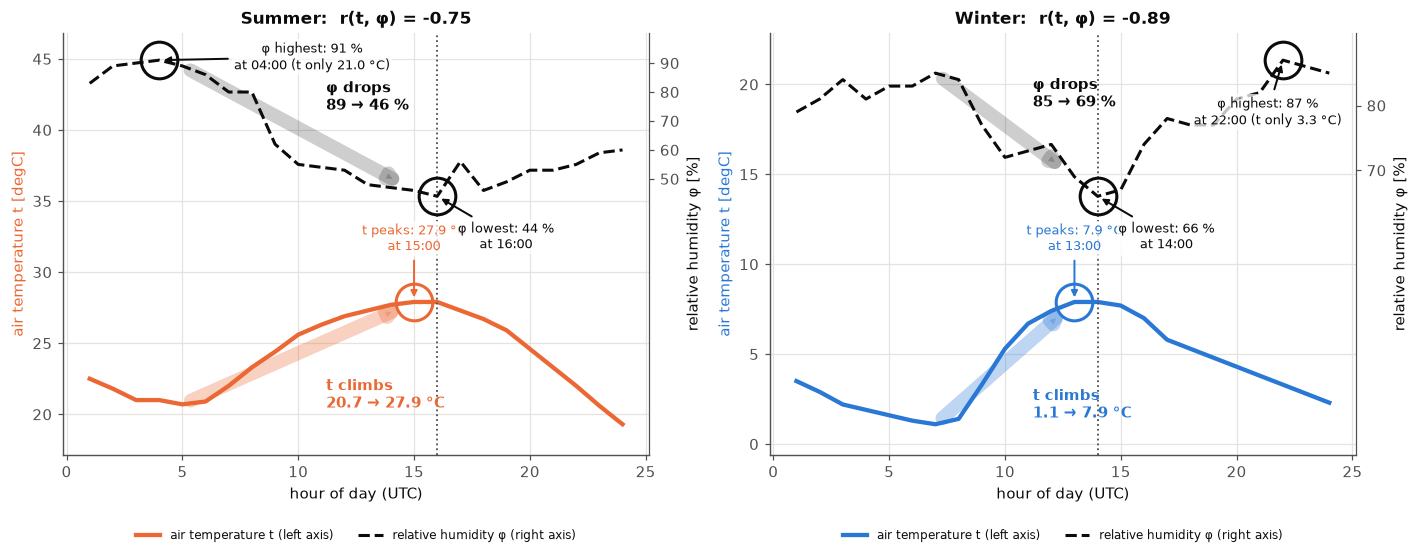

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True)
for ax, (n, (d, col)) in zip(axs, DAYS.items()):
    t, rh = d["t"], d["RH"]; Rt, Rr = np.ptp(t), np.ptp(rh)
    ax.plot(hours, t, color=col, lw=2.8, label="air temperature t (left axis)")                  # t lives in the lower band, phi in the upper band
    ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("air temperature t [degC]", color=col)
    ax.set_ylim(t.min() - 0.25 * Rt, t.max() + 2.2 * Rt)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(hours, rh, color=INK, lw=2, ls="--", label="relative humidity φ (right axis)")
    ax2.set_ylabel("relative humidity φ [%]"); ax2.set_ylim(rh.min() - 1.9 * Rr, rh.max() + 0.2 * Rr)
    ax2.set_yticks(np.arange(np.ceil(rh.min() / 10) * 10, rh.max() + 1, 10))
    it, il, ir = int(t.argmax()), int(rh.argmin()), int(rh.argmax())
    i0 = int(t[:it + 1].argmin())                                      # coolest hour before the peak
    ax.annotate("", (hours[it], t[it]), (hours[i0], t[i0]), arrowprops=dict(arrowstyle="-|>", color=col, lw=9, alpha=0.30, shrinkA=6, shrinkB=6))
    ax2.annotate("", (hours[it], rh[it]), (hours[i0], rh[i0]), arrowprops=dict(arrowstyle="-|>", color=INK, lw=9, alpha=0.20, shrinkA=6, shrinkB=6))
    ax.text((hours[i0] + hours[it]) / 2 + 1.2, (t[i0] + t[it]) / 2 - 0.2 * Rt, f"t climbs\n{t[i0]:.1f} → {t[it]:.1f} °C", color=col, fontweight="bold", ha="left", va="top", fontsize=9.5)
    ax2.text((hours[i0] + hours[it]) / 2 + 1.2, (rh[i0] + rh[it]) / 2 + 0.1 * Rr, f"φ drops\n{rh[i0]:.0f} → {rh[it]:.0f} %", color=INK, fontweight="bold", ha="left", va="bottom", fontsize=9.5)
    ax.axvline(hours[il], color=MUTED, ls=":", lw=1.2)
    ring(ax, hours[it], t[it], color=col); ring(ax2, hours[il], rh[il], color=INK); ring(ax2, hours[ir], rh[ir], color=INK)
    point(ax, (hours[it], t[it]), f"t peaks: {t[it]} °C\nat {hours[it]:02d}:00", (0, 34), color=col)
    point(ax2, (hours[il], rh[il]), f"φ lowest: {rh[il]} %\nat {hours[il]:02d}:00", (45, -34), color=INK)
    point(ax2, (hours[ir], rh[ir]), f"φ highest: {rh[ir]} %\nat {hours[ir]:02d}:00 (t only {t[ir]} °C)", (100, -6) if n == "Summer" else (-10, -42), color=INK)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.15))
    ax.set_title(f"{n}:  r(t, φ) = {corr(d, 't', 'RH'):+.2f}")
plt.tight_layout(); plt.show()

### 3. Dew point and grams of water: the same curve

The dew point is just the water amount ($p_v$) written as a temperature, and $x$ is the same amount written in grams per kg. So the two lines are copies of each other. In the first two panels the dashed line ($x$) sits on top of the solid line (dew point); the axes are scaled so you can see it. The dotted lines and circles mark the highest and lowest hours: **both turn at the same hour** ($r=1.00$).
- **Summer:** both highest at 02:00 (dew point 19.9 °C, 14.8 g/kg), both lowest at 24:00 (11.3 °C, 8.5 g/kg).
- **Winter:** both highest at 12:00 (3.1 °C, 4.8 g/kg), both lowest at 06:00 (−1.3 °C, 3.5 g/kg).

The right panel: all 48 hours lie on **one curve, the 100 % curve of A2** (the "full sponge" line). That is what the dew point means: air with this much water is exactly full at the temperature where it meets that curve. Summer is high on the curve (humid), winter low on it (dry).

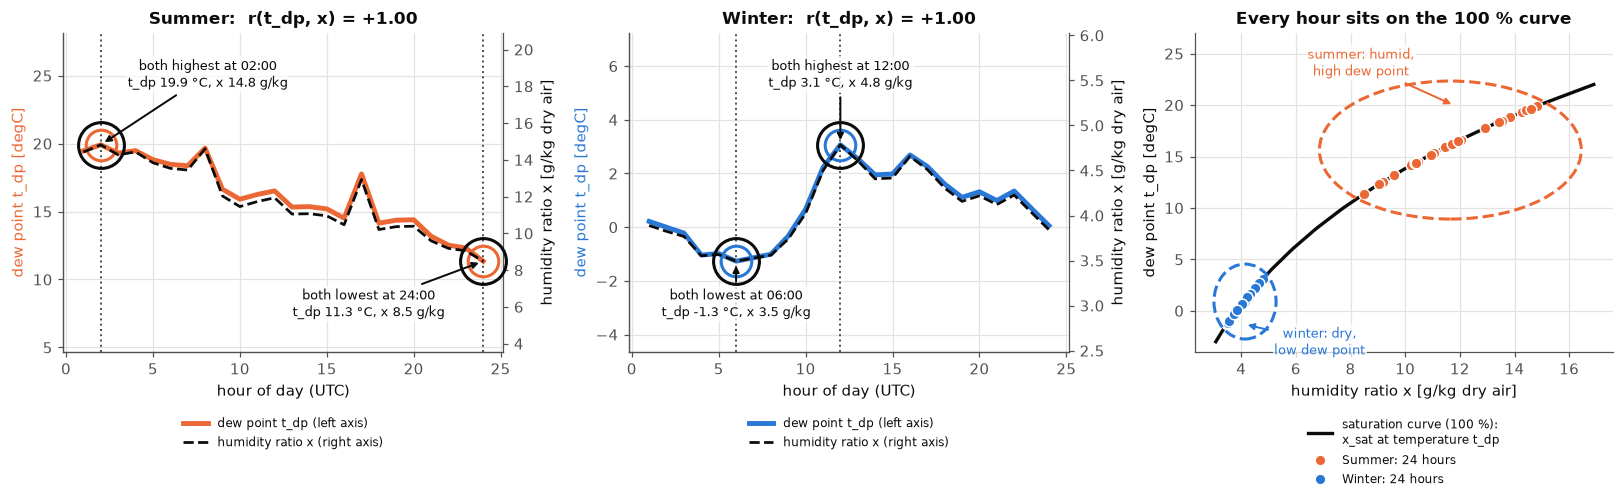

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.95]))
for ax, (n, (d, col)) in zip(axs[:2], DAYS.items()):
    tdp, xx = d["tdp"], d["x"]
    s = np.ptp(xx) / np.ptp(tdp); m = 0.3 * np.ptp(tdp)                 # scale the two axes so the curves can overlay
    ax.plot(hours, tdp, color=col, lw=3.2, label="dew point t_dp (left axis)")
    ax.set_ylim(tdp.min() - 2.6 * m, tdp.max() + 3.2 * m); ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("dew point t_dp [degC]", color=col)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(hours, xx, color=INK, lw=1.8, ls="--", label="humidity ratio x (right axis)")
    ax2.set_ylim(xx.min() - 2.6 * m * s, xx.max() + 3.2 * m * s); ax2.set_ylabel("humidity ratio x [g/kg dry air]")
    for i, word in ((int(xx.argmax()), "highest"), (int(xx.argmin()), "lowest")):
        ax.axvline(hours[i], color=MUTED, ls=":", lw=1.3); ring(ax, hours[i], tdp[i], color=col, size=20); ring(ax2, hours[i], xx[i], color=INK, size=30)
        off = {"highest": (70 if hours[i] < 6 else 0, 38), "lowest": (-75 if hours[i] > 18 else 0, -36)}[word]
        point(ax2, (hours[i], xx[i]), f"both {word} at {hours[i]:02d}:00\nt_dp {tdp[i]:.1f} °C, x {xx[i]:.1f} g/kg", off, color=INK)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", ncol=1, fontsize=8, bbox_to_anchor=(0.5, -0.17))
    ax.set_title(f"{n}:  r(t_dp, x) = {corr(d, 'tdp', 'x'):+.2f}")
ax = axs[2]
tc = np.linspace(-3, 22, 100); ax.plot(1000 * humidity_ratio(p_sat(tc)), tc, color=INK, lw=2.2, label="saturation curve (100 %):\nx_sat at temperature t_dp")
for n, (d, col) in DAYS.items():
    ax.plot(d["x"], d["tdp"], "o", color=col, ms=7, mec="white", label=f"{n}: 24 hours")
    blob(ax, d["x"], d["tdp"], col, 0.4, 1.0)
point(ax, (DAYS["Summer"][0]["x"].mean(), DAYS["Summer"][0]["tdp"].max()), "summer: humid,\nhigh dew point", (-62, 20), color=SUMMER)
point(ax, (DAYS["Winter"][0]["x"].mean(), DAYS["Winter"][0]["tdp"].min()), "winter: dry,\nlow dew point", (50, -20), color=WINTER)
ax.set_ylim(-4, 27); ax.set_xlabel("humidity ratio x [g/kg dry air]"); ax.set_ylabel("dew point t_dp [degC]"); ax.legend(frameon=False, loc="upper center", fontsize=8, bbox_to_anchor=(0.5, -0.17))
ax.set_title("Every hour sits on the 100 % curve")
plt.tight_layout(); plt.show()

### 4. The gap to the dew point and the percentage

The gap $t-t_{dp}$ is how many degrees the air must cool before the sponge is full. A small gap means nearly full; **gap 0 means exactly 100 %** (the star). The dots fall on a line sloping down from the star ($r=-1.00$): the bigger the gap, the drier the air.
- **Summer night** (01:00 to 08:00): gap 1.5 to 3.6 °C, 80 to 91 %: nearly fog.
- **Summer afternoon** (12:00 to 16:00): gap 10.4 to 13.4 °C, 44 to 53 %: dry end of the line.
- **Winter**: gap 2.0 to 5.9 °C, 66 to 87 %: always close to fog, even though there is very little water in the air.

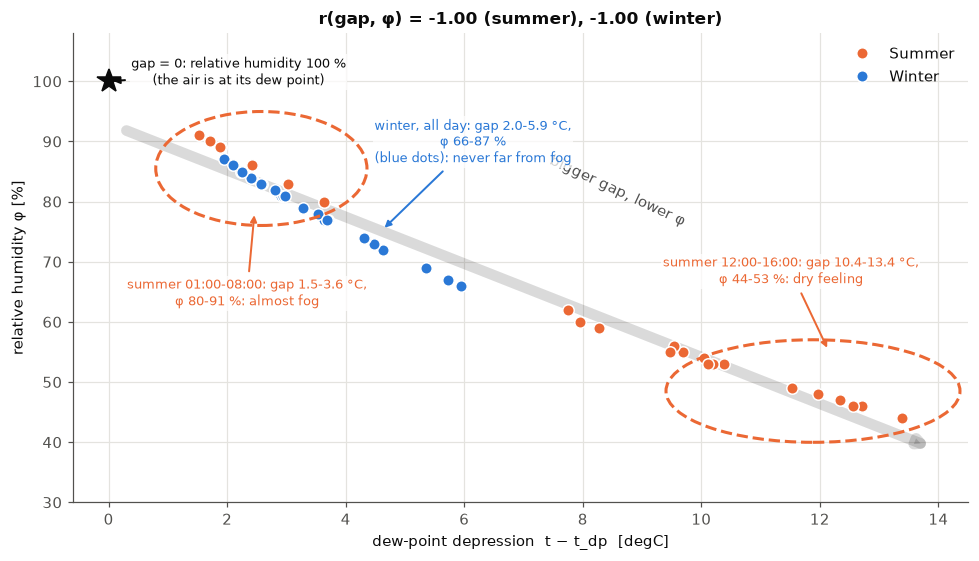

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.2))
allg = np.concatenate([d["gap"] for d, _ in DAYS.values()]); allr = np.concatenate([d["RH"] for d, _ in DAYS.values()]); fit = np.polyfit(allg, allr, 1)
for n, (d, col) in DAYS.items():
    ax.plot(d["gap"], d["RH"], "o", color=col, ms=7.5, mec="white", label=n, zorder=5)
ax.annotate("", (allg.max() + 0.5, np.polyval(fit, allg.max() + 0.5)), (0.3, np.polyval(fit, 0.3)), arrowprops=dict(arrowstyle="-|>", color=INK, lw=7, alpha=0.15, shrinkA=0, shrinkB=0))
ax.plot(0, 100, "*", color=INK, ms=16, zorder=7); point(ax, (0, 100), "gap = 0: relative humidity 100 %\n(the air is at its dew point)", (85, -2), color=INK)
S, W = DAYS["Summer"][0], DAYS["Winter"][0]
night, aft = slice(0, 8), slice(11, 16)
blob(ax, S["gap"][night], S["RH"][night], SUMMER, 0.5, 3); blob(ax, S["gap"][aft], S["RH"][aft], SUMMER, 0.6, 4)
point(ax, (S["gap"][night].mean(), S["RH"][night].min() - 1.5), f"summer 01:00-08:00: gap {S['gap'][night].min():.1f}-{S['gap'][night].max():.1f} °C,\nφ {S['RH'][night].min()}-{S['RH'][night].max()} %: almost fog", (-5, -62), color=SUMMER)
point(ax, (S["gap"][aft].mean(), S["RH"][aft].max() + 2), f"summer 12:00-16:00: gap {S['gap'][aft].min():.1f}-{S['gap'][aft].max():.1f} °C,\nφ {S['RH'][aft].min()}-{S['RH'][aft].max()} %: dry feeling", (-25, 45), color=SUMMER)
point(ax, (4.6, np.polyval(fit, 4.6)), f"winter, all day: gap {W['gap'].min():.1f}-{W['gap'].max():.1f} °C,\nφ {W['RH'].min()}-{W['RH'].max()} %\n(blue dots): never far from fog", (60, 45), color=WINTER)
ax.text(7.4, 76, "bigger gap, lower φ", color=INK, rotation=-25, alpha=0.7, fontsize=10)
ax.set_xlabel("dew-point depression  t − t_dp  [degC]"); ax.set_ylabel("relative humidity φ [%]"); ax.set_xlim(-0.6, 14.5); ax.set_ylim(30, 108); ax.legend(frameon=False, loc="upper right")
ax.set_title(f"r(gap, φ) = {corr(S, 'gap', 'RH'):+.2f} (summer), {corr(W, 'gap', 'RH'):+.2f} (winter)")
plt.tight_layout(); plt.show()

### 5. Energy: does it follow the warmth or the water?

$h$ = warmth ($t$) + hidden energy (proportional to $x$), so it follows whichever of the two moves more. Each panel plots $h$ against one of them; the wide stripe is the trend and the label tells you if the dots make a tight line or a loose cloud.
- **Winter** ($r=0.99$ with $t$, $0.96$ with $x$): warmth and water rise together, so $h$ follows both. The warmth part moves 6.8 kJ/kg over the day, the hidden part only 3.3, so warmth leads.
- **Summer** ($r=0.33$ with $t$, $0.84$ with $x$): warmth and water are strangers ($r=-0.23$), because the humid hours are the cool night hours. The hidden part moves 16.1 kJ/kg and the warmth part only 8.6, so the **water leads**. The temperature panel is a cloud, the water panel a tighter line.
- **The circles in the summer panels:** at 08:00 the air is only 23.3 °C but its energy is the day's highest (60.4 kJ/kg), because it holds 14.6 g/kg of water. At 24:00 it is the coolest and driest hour, with the lowest energy (40.8 kJ/kg).

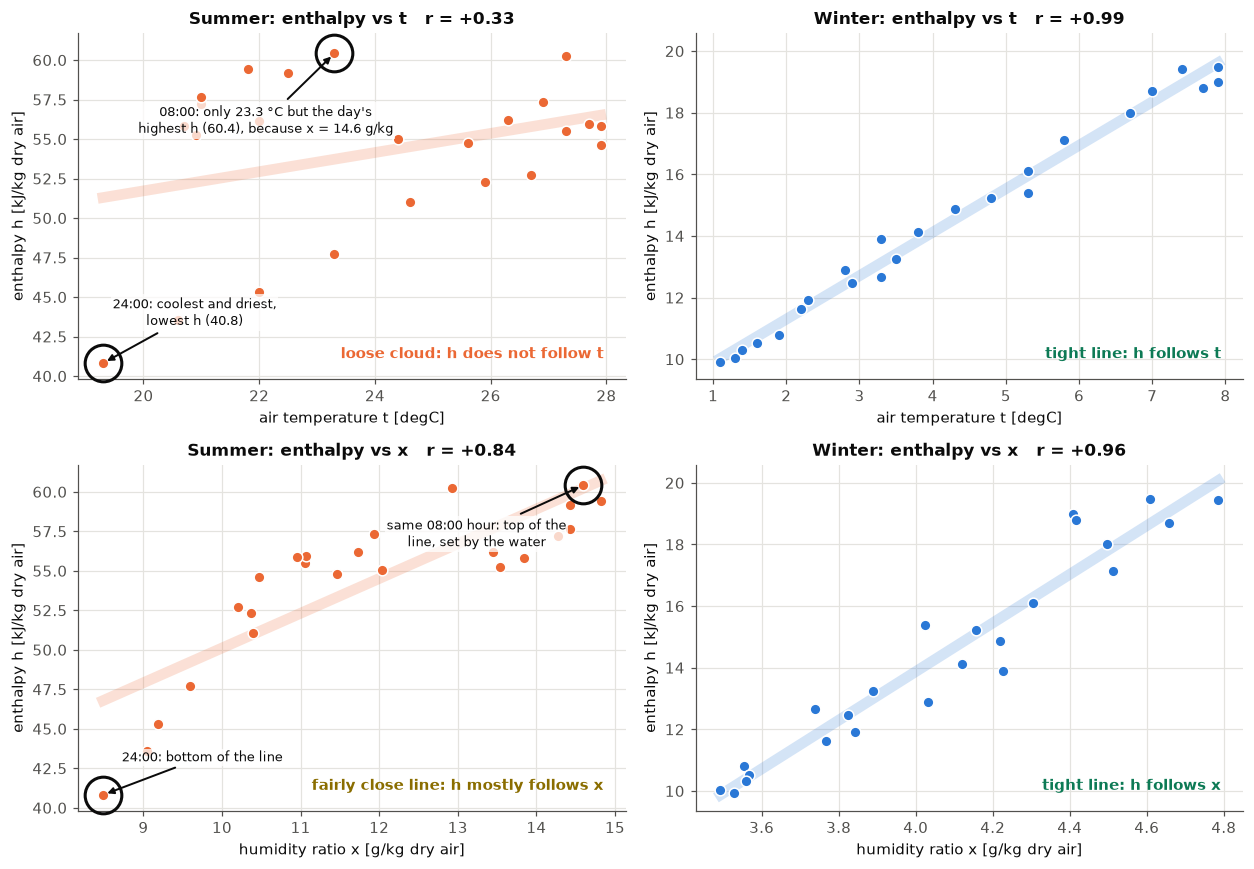

In [20]:
fig, axs = plt.subplots(2, 2, figsize=(11.5, 8), sharey="col")
for j, (n, (d, col)) in enumerate(DAYS.items()):
    for i, (key, xl) in enumerate((("t", "air temperature t [degC]"), ("x", "humidity ratio x [g/kg dry air]"))):
        ax = axs[i, j]; k = np.polyfit(d[key], d["h"], 1); xs_ = np.array([d[key].min(), d[key].max()])
        ax.plot(xs_, np.polyval(k, xs_), color=col, lw=7, alpha=0.2)
        ax.plot(d[key], d["h"], "o", color=col, ms=7, mec="white")
        r = corr(d, key, "h"); verdict, vcol = (f"tight line: h follows {key}", "#0d7a55") if abs(r) > 0.9 else ((f"fairly close line: h mostly follows {key}", "#8a6d00") if abs(r) > 0.6 else (f"loose cloud: h does not follow {key}", ORANGE))
        ax.set_title(f"{n}: enthalpy vs {key}   r = {r:+.2f}", color=INK)
        ax.text(0.96, 0.05, verdict, transform=ax.transAxes, ha="right", va="bottom", color=vcol, fontweight="bold", fontsize=9.5)
        ax.set_xlabel(xl); ax.set_ylabel("enthalpy h [kJ/kg dry air]")
S = DAYS["Summer"][0]; ih, il = int(S["h"].argmax()), int(S["h"].argmin())
for i, key in enumerate(("t", "x")):
    ring(axs[i, 0], S[key][ih], S["h"][ih], color=INK); ring(axs[i, 0], S[key][il], S["h"][il], color=INK)
point(axs[0, 0], (S["t"][ih], S["h"][ih]), f"{hours[ih]:02d}:00: only {S['t'][ih]} °C but the day's\nhighest h ({S['h'][ih]:.1f}), because x = {S['x'][ih]:.1f} g/kg", (-45, -52), color=INK)
point(axs[0, 0], (S["t"][il], S["h"][il]), f"{hours[il]:02d}:00: coolest and driest,\nlowest h ({S['h'][il]:.1f})", (60, 25), color=INK)
point(axs[1, 0], (S["x"][ih], S["h"][ih]), f"same {hours[ih]:02d}:00 hour: top of the\nline, set by the water", (-70, -40), color=INK)
point(axs[1, 0], (S["x"][il], S["h"][il]), f"{hours[il]:02d}:00: bottom of the line", (65, 22), color=INK)
plt.tight_layout(); plt.show()

# Part B: Sheet 2, will a person feel comfortable?

## B0. The big idea: your body is a little campfire

Your body **makes heat** all the time (even asleep). The room **takes heat away**. Think of a **bathtub**: the tap is the heat you make, the drains are the ways the room steals it.

- Drains take **exactly** what the tap gives → water level steady → you feel **just right**.
- Drains take **less** → level rises → you feel **hot**.
- Drains take **more** → level sinks → you feel **cold**.

The number that says "how high is the water level" is the **PMV** (Predicted Mean Vote). We then count how many people out of 100 would complain: the **PPD** (Predicted Percentage of Dissatisfied).

**Metabolic rate** is how much heat your body makes (the tap). It is measured in **met**: 1 met is a person sitting quietly, about 58 W of heat for every square metre of skin (a **watt**, W, is energy per second).

![Six things decide if a person feels comfortable](../images/pmv-six-factors.svg)

*Figure: Six things decide if a person feels comfortable*

The six factors in the picture:

* **Air temperature $t_a$**: what a normal thermometer says, in °C.
* **Mean radiant temperature $t_{mr}$**: how warm the **walls and windows** are. You feel a cold window even when the air is warm. In °C.
* **Air speed $v$**: how strong the breeze is. Wind steals heat. In m/s.
* **Relative humidity**: how sticky the air is (Part A's sponge). Sticky air makes sweating less effective. In %.
* **Clothing insulation $I_{clo}$**: how warm your clothes are, like a blanket around the bathtub. Measured in **clo** (0.5 = light summer clothes, 1 = a winter suit).
* **Activity**: the metabolic rate $M$ from above (sitting ≈ 1 met, running much more).

### What do PMV and PPD stand for?

**PMV = Predicted Mean Vote.** A scientist called Fanger (Denmark, 1960s) put volunteers in special rooms, changed the temperature, wetness of the air, wind and clothes, and asked everybody to **vote** on a scale: −3 cold, −2 cool, −1 slightly cool, **0 just right**, +1 slightly warm, +2 warm, +3 hot.
- **Vote** = one person's answer.
- **Mean** = the *average* of a big group (add all votes, divide by the number of people).
- **Predicted** = we don't ask anyone. We **calculate** the vote with the body's heat balance (the bathtub: heat made minus heat lost).

**PPD = Predicted Percentage of Dissatisfied.** Even when the *average* person is happy, some people are not. PPD says how many out of 100 would complain, meaning they feel **warm or hot (+2, +3) or cool or cold (−2, −3)**. It is never below 5 %: you can't please everyone.

**ISO 7730** is the official rule-book that says how to calculate PMV and PPD (ISO = International Organization for Standardization). **ASHRAE 55** is a similar rule-book from a club of heating and cooling engineers (American Society of Heating, Refrigerating and Air-Conditioning Engineers).


## B1. Clothes are a guessing game

The clothes' outer surface has a temperature $t_{cl}$ that we don't know, but we need it to compute the heat that leaves through the clothes. And that heat itself depends on $t_{cl}$! A chicken-and-egg problem. The trick: **guess, improve, repeat** until the guess stops changing (this is called an *iteration*). The sheet asks us to count how many rounds it takes (we stop when the change is below 0.0015).

![More clothes or more movement means you feel warmer](../images/clothing-and-activity.svg)

*Figure: More clothes or more movement means you feel warmer*

![Guess, check, improve, repeat: the clothing-temperature game](../images/tcl-iteration.svg)

*Figure: Guess, check, improve, repeat: the clothing-temperature game*

Outdoor: PMV = 1.767, PPD = 65.3 %, operative temperature = 30.25 degC, rounds of guessing = 8


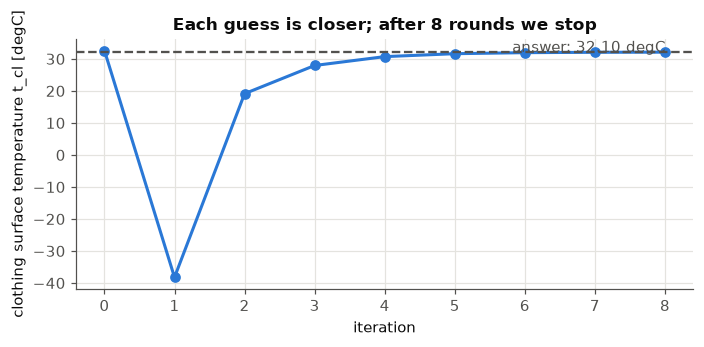

In [21]:
# outdoor summer case from the sheet: 30 degC air, 30.5 degC walls, 0.15 m/s, 60 % RH, 0.5 clo, 1.2 met
pmv, ppd, t_o, n, d = calculate_pmv_ppd(30, 30.5, details=True)
print(f"Outdoor: PMV = {pmv:.3f}, PPD = {ppd:.1f} %, operative temperature = {t_o:.2f} degC, rounds of guessing = {n}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(range(len(d['history'])), d['history'], "o-", color=BLUE, lw=2)
ax.axhline(d['t_cl'], color=MUTED, ls="--"); ax.text(len(d['history']) - 1, d['t_cl'] + 0.1, f"answer: {d['t_cl']:.2f} degC", ha="right", color=MUTED)
ax.set_xlabel("iteration"); ax.set_ylabel("clothing surface temperature t_cl [degC]")
ax.set_title("Each guess is closer; after 8 rounds we stop")
plt.tight_layout(); plt.show()

**Reading it.** The first guess is a bit off, then each round gets closer, like finding a hidden toy by being told "warmer, warmer, ...". We stop when the answer moves less than 0.0015 (that is 0.15 °C). The sheet's answer is **8 rounds**.

## B2. Where does the heat go? (the 6 drains)

The body loses heat through six paths. Each one is a **heat flux**, the heat per second flowing through one square metre of skin, in W/m²:

- **RL1**: Water slowly seeping out through the skin
- **RL2**: Sweating (only if you make more heat than when resting)
- **RL3**: Water vapour you breathe out
- **RL4**: Warm air you breathe out
- **RL5**: Heat radiating from your clothes to the walls
- **RL6**: Air carrying heat away from your clothes (breeze)

What is left over is the **thermal load** $L = M - RL1 - \dots - RL6$. Then **PMV = (sensitivity) × L**, where the *sensitivity* is a fixed number that turns the left-over heat into a vote. Positive means heat piles up (hot), negative means too much leaves (cold).

![Your body is a little heater that gives its heat away in several ways](../images/body-heat-exchange.svg)

*Figure: Your body is a little heater that gives its heat away in several ways*

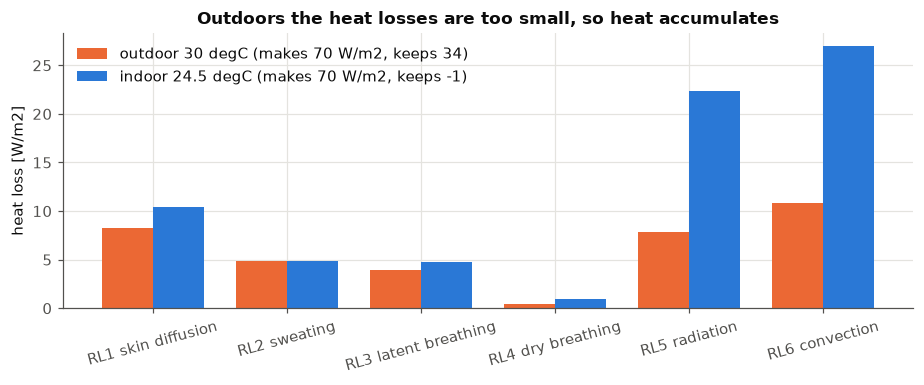

In [22]:
pm_in, pp_in, to_in, n_in, d_in = calculate_pmv_ppd(24.5, 25, details=True)
labels = ["RL1 skin diffusion", "RL2 sweating", "RL3 latent breathing", "RL4 dry breathing", "RL5 radiation", "RL6 convection"]
out = [d[k] for k in ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]]
ins = [d_in[k] for k in ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]]
x = np.arange(6); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(x - w/2, out, w, color=ORANGE, label=f"outdoor 30 degC (makes {d['M']:.0f} W/m2, keeps {d['L']:.0f})")
ax.bar(x + w/2, ins, w, color=BLUE, label=f"indoor 24.5 degC (makes {d_in['M']:.0f} W/m2, keeps {d_in['L']:.0f})")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15); ax.set_ylabel("heat loss [W/m2]"); ax.legend(frameon=False)
ax.set_title("Outdoors the heat losses are too small, so heat accumulates")
plt.tight_layout(); plt.show()

**Reading it.** The body makes about 70 W/m² in both cases. Indoors, the drains take away almost exactly that (little is left over → PMV ≈ 0). Outdoors, the radiation and breeze drains (RL5, RL6) nearly vanish because the air is as warm as your clothes, so about 30 W/m² piles up → you feel hot.

## B3. From heat left over to a vote (PMV) and complaints (PPD)

- **PMV** scale: −3 cold, −2 cool, −1 slightly cool, **0 neutral**, +1 slightly warm, +2 warm, +3 hot.
- **PPD** is the % unhappy. Even at a perfect PMV = 0, 5 % of people complain (we are all different!).
- The **operative temperature** $t_o$ printed below is the "feels-like" temperature of the room: a mix of the air temperature and the wall temperature.
- A room is called **category I** (very good) when PMV is within ±0.2, category II within ±0.5, category III within ±0.7.

![From cold to hot: the comfort vote](../images/pmv-scale.svg)

*Figure: From cold to hot: the comfort vote*

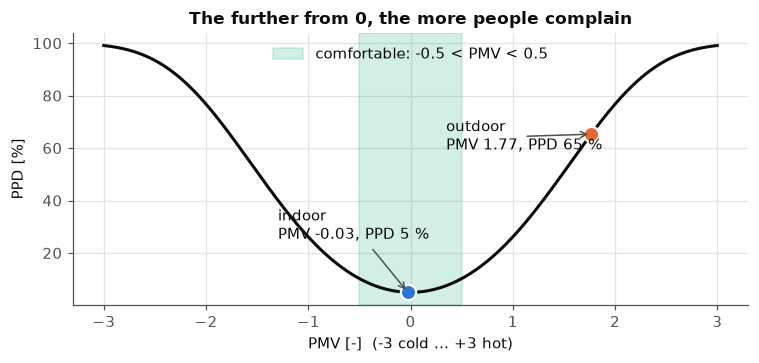

In [23]:
pv_ = np.linspace(-3, 3, 300)
ppd_ = 100 - 95 * np.exp(-0.03353 * pv_**4 - 0.2179 * pv_**2)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(-0.5, 0.5, color=AQUA, alpha=0.2, label="comfortable: -0.5 < PMV < 0.5")
ax.plot(pv_, ppd_, color=INK, lw=2)
ax.plot(pm_in, pp_in, "o", color=BLUE, ms=10, mec="white", mew=1.5); ax.annotate(f"indoor\nPMV {pm_in:.2f}, PPD {pp_in:.0f} %", (pm_in, pp_in), xytext=(-85, 35), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=MUTED))
ax.plot(pmv, ppd, "o", color=ORANGE, ms=10, mec="white", mew=1.5); ax.annotate(f"outdoor\nPMV {pmv:.2f}, PPD {ppd:.0f} %", (pmv, ppd), xytext=(-95, -10), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set_xlabel("PMV [-]  (-3 cold ... +3 hot)"); ax.set_ylabel("PPD [%]"); ax.legend(frameon=False, loc="upper center")
ax.set_title("The further from 0, the more people complain")
plt.tight_layout(); plt.show()

**Reading it.** The curve is a bowl: lowest at 0 (5 %), rising fast on both sides. Outdoors (PMV 1.77) about **65 %** are unhappy; our indoor room (PMV −0.03) is at the bottom of the bowl, **5 %**.

## B4. Finding the right indoor temperature (the second half of the sheet)

We keep the same person (light clothes 0.5 clo, sitting 1.2 met, 60 % humidity, almost no breeze) and try air temperatures from 18 to 30 °C. In summer the walls are about 0.5 °C warmer than the air ($t_{mr} = t_a + 0.5$). We look for where **PMV stays between −0.5 and +0.5**.

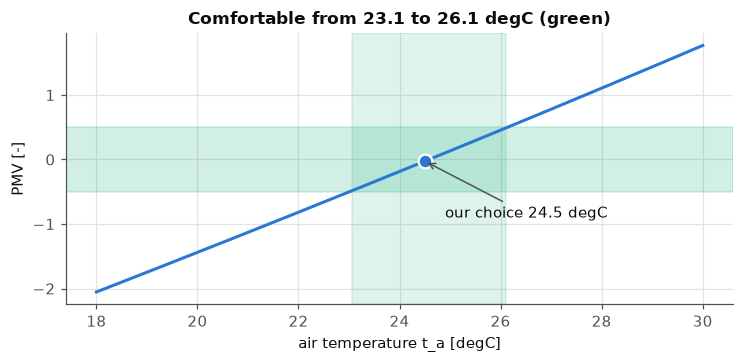

In [24]:
ta = np.linspace(18, 30, 241)
pm = np.array([calculate_pmv_ppd(t, t + 0.5)[0] for t in ta])
ok = ta[np.abs(pm) < 0.5]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axhspan(-0.5, 0.5, color=AQUA, alpha=0.2)
ax.plot(ta, pm, color=BLUE, lw=2)
ax.axvspan(ok.min(), ok.max(), color=AQUA, alpha=0.15)
ax.plot(24.5, pm_in, "o", color=BLUE, ms=9, mec="white", mew=1.5); ax.annotate("our choice 24.5 degC", (24.5, pm_in), xytext=(24.9, -0.9), arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set_xlabel("air temperature t_a [degC]"); ax.set_ylabel("PMV [-]")
ax.set_title(f"Comfortable from {ok.min():.1f} to {ok.max():.1f} degC (green)")
plt.tight_layout(); plt.show()

**Reading it.** The blue line climbs as the room gets warmer. The green zone is where people say "just right": about **23.0 to 26.1 °C**. We picked **24.5 °C** (air) / **25 °C** (walls): PMV = −0.03, PPD = 5 %, category I. Try clothes of 1.0 clo or activity of 2.0 met in the call above and watch the green zone slide down: **warmer clothes or more movement means you want a cooler room**.

## B5. Cheat-sheet

- **Water pressure, grams of water, dew point, energy for summer / winter day** (sheet 1): A3 results: 16.26 / 3.25 g/kg, 21.37 / −2.23 °C, 71.56 / 8.12 kJ/kg
- **Mass of air in the 6×4×3 m room** (sheet 1): 84.14 kg (1.17 kg/m³)
- **PMV, PPD, $t_o$, rounds (outdoor 30 / 30.5 °C)** (sheet 2): 1.767, 65.3 %, 30.25 °C, 8
- **Indoor state with −0.5 < PMV < 0.5** (sheet 2): 24.5 / 25 °C → PMV −0.03, PPD 5.0 %, $t_o$ 24.75 °C

**One sentence for each sheet:** *Sheet 1:* "Warm air has a big sponge, so summer air carries far more water and energy than winter air." *Sheet 2:* "Comfort is when the heat your body makes equals the heat the room takes away."